## 1. Imports & config

In [49]:
import os
import pickle
from itertools import product

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

import astropy.table as at
import astropy.units as u
import astropy.coordinates as coord
from astropy.table import Table
from astropy.coordinates import SkyCoord, Distance
from matplotlib.path import Path

import jax
import jax.numpy as jnp
import jax.random as jr

import arviz as az
import numpyro
import numpyro.distributions as dist
import numpyro.infer as infer

from scipy.stats import binned_statistic
from scipy.optimize import brentq
from tqdm import tqdm

jax.config.update("jax_enable_x64", True)
%matplotlib inline

## 2. Load tables & selection cuts → `t_final`

Loads the FITS tables, applies the pre-chem selection, the low-α + [Fe/H] cut, and
the [Al/Fe]-[Mg/Mn] polygon cut. Ends with `t_final`.

In [31]:
t2 = Table.read("astraAllStarAstroNNdist-0.8.0-bugfix20260709.fits", format="fits", hdu=2)
t2.colnames

['sdss_id',
 'sdss4_apogee_id',
 'gaia_dr2_source_id',
 'gaia_dr3_source_id',
 'tic_v8_id',
 'healpix',
 'lead',
 'version_id',
 'catalogid',
 'catalogid21',
 'catalogid25',
 'catalogid31',
 'n_associated',
 'n_neighborhood',
 'crossmatch_flags',
 'sdss5_target_flags',
 'sdss4_apogee_target1_flags',
 'sdss4_apogee_target2_flags',
 'sdss4_apogee2_target1_flags',
 'sdss4_apogee2_target2_flags',
 'sdss4_apogee2_target3_flags',
 'sdss4_apogee_member_flags',
 'sdss4_apogee_extra_target_flags',
 'ra',
 'dec',
 'l',
 'b',
 'plx',
 'e_plx',
 'pmra',
 'e_pmra',
 'pmde',
 'e_pmde',
 'gaia_v_rad',
 'gaia_e_v_rad',
 'g_mag',
 'bp_mag',
 'rp_mag',
 'j_mag',
 'e_j_mag',
 'h_mag',
 'e_h_mag',
 'k_mag',
 'e_k_mag',
 'ph_qual',
 'bl_flg',
 'cc_flg',
 'w1_mag',
 'e_w1_mag',
 'w1_flux',
 'w1_dflux',
 'w1_frac',
 'w2_mag',
 'e_w2_mag',
 'w2_flux',
 'w2_dflux',
 'w2_frac',
 'w1uflags',
 'w2uflags',
 'w1aflags',
 'w2aflags',
 'mag4_5',
 'd4_5m',
 'rms_f4_5',
 'sqf_4_5',
 'mf4_5',
 'csf',
 'zgr_teff',
 'zgr_

In [32]:
t2_sdss_id = np.asarray(t2["sdss_id"])
dist_col = np.asarray(t2["dist_bugfix"], float)
print("dist_bugfix shape:", dist_col.shape)  # check for the (N,1) quirk like AgeJTsketchy had
if dist_col.ndim > 1:
    dist_col = dist_col.ravel()

# any crossmatch at all
has_any_t2_match = np.isin(final_sdss_id, t2_sdss_id)

# valid: finite, not the -1 fill sentinel, and within a sane physical range (<50 kpc in pc)
valid_dist_mask = (
    np.isfinite(dist_col)
    & (dist_col > 0) & (dist_col < 50_000)
    & (t2_sdss_id != -1)
)
t2_sdss_id_valid = t2_sdss_id[valid_dist_mask]
has_valid_dist = np.isin(final_sdss_id, t2_sdss_id_valid)

print(f"t_final stars with ANY t2 match: {has_any_t2_match.sum()} / {len(t_final)} "
      f"({100 * has_any_t2_match.sum() / len(t_final):.1f}%)")

print(f"t_final stars with a valid dist_bugfix: {has_valid_dist.sum()} / {len(t_final)} "
      f"({100 * has_valid_dist.sum() / len(t_final):.1f}%)")

matched_but_check = has_any_t2_match.sum()
if matched_but_check > 0:
    print(f"of t_final stars with a t2 match, fraction with valid dist_bugfix: "
          f"{100 * has_valid_dist.sum() / matched_but_check:.1f}%")

print("t2 sdss_id == -1 count:", np.sum(t2_sdss_id == -1))
print("t2 sdss_id == 0 count:", np.sum(t2_sdss_id == 0))

dist_bugfix shape: (2408246,)
t_final stars with ANY t2 match: 387575 / 391384 (99.0%)
t_final stars with a valid dist_bugfix: 233068 / 391384 (59.5%)
of t_final stars with a t2 match, fraction with valid dist_bugfix: 60.1%
t2 sdss_id == -1 count: 68
t2 sdss_id == 0 count: 1


In [33]:
n_total_t2 = len(t2_sdss_id)
n_not_finite = np.sum(~np.isfinite(dist_col))
n_nonpositive = np.sum(np.isfinite(dist_col) & (dist_col <= 0))
n_too_far = np.sum(np.isfinite(dist_col) & (dist_col >= 50_000))

print(f"t2 rows total: {n_total_t2}")
print(f"  not finite (NaN/inf): {n_not_finite} ({100*n_not_finite/n_total_t2:.1f}%)")
print(f"  finite but <= 0: {n_nonpositive} ({100*n_nonpositive/n_total_t2:.1f}%)")
print(f"  finite but >= 50 kpc: {n_too_far} ({100*n_too_far/n_total_t2:.1f}%)")

t2 rows total: 2408246
  not finite (NaN/inf): 1179048 (49.0%)
  finite but <= 0: 0 (0.0%)
  finite but >= 50 kpc: 16509 (0.7%)


In [25]:
t3 = Table.read("StarFlow_summary_v1_0_0.fits", format="fits", hdu=1)
t3["sdss4_apogee_id"] = t3["sdss4_apogee_id"].filled(-1)

dr17 = Table.read("allStarLite-dr17-synspec_rev1.fits", hdu=1)
t3 = at.join(
    t3,
    dr17["APOGEE_ID", "SNR", "VHELIO_AVG"],
    keys_left="sdss4_apogee_id",
    keys_right="APOGEE_ID",
    join_type="left",
)
print("loaded StarFlow_summary_v1_0_0:", len(t3))
t3.colnames

loaded StarFlow_summary_v1_0_0: 1287381


['sdss_id',
 'sdss4_apogee_id',
 'age',
 'e_p_age',
 'e_n_age',
 'mass',
 'e_p_mass',
 'e_n_mass',
 'training_density',
 'BITMASK',
 'APOGEE_ID',
 'SNR',
 'VHELIO_AVG']

In [26]:
t3_sdss_id = np.asarray(t3["sdss_id"])
age_col = np.asarray(t3["age"], float)
if age_col.ndim > 1:
    age_col = age_col.ravel()

# any crossmatch at all, ignoring whether age is valid
has_any_t3_match = np.isin(final_sdss_id, t3_sdss_id)

# valid: finite age, not the -1 fill sentinel
valid_age_mask = np.isfinite(age_col) & (t3_sdss_id != -1)
t3_sdss_id_valid = t3_sdss_id[valid_age_mask]
has_valid_age = np.isin(final_sdss_id, t3_sdss_id_valid)

print(f"RGB stars with ANY StarFlow_summary_v1_0_0 match: {has_any_t3_match.sum()} / {len(t_final)} "
      f"({100 * has_any_t3_match.sum() / len(t_final):.1f}%)")

print(f"RGB stars with a valid age: {has_valid_age.sum()} / {len(t_final)} "
      f"({100 * has_valid_age.sum() / len(t_final):.1f}%)")

matched_but_check = has_any_t3_match.sum()
if matched_but_check > 0:
    print(f"of RGB stars with a StarFlow_summary_v1_0_0 match, fraction with valid age: "
          f"{100 * has_valid_age.sum() / matched_but_check:.1f}%")

print("t3 sdss_id == -1 count:", np.sum(t3_sdss_id == -1))

RGB stars with ANY StarFlow_summary_v1_0_0 match: 213804 / 391384 (54.6%)
RGB stars with a valid age: 210837 / 391384 (53.9%)
of RGB stars with a StarFlow_summary_v1_0_0 match, fraction with valid age: 98.6%
t3 sdss_id == -1 count: 8


In [50]:
t4 = Table.read("IPL42_agesJT.fits", format="fits")
print(t4.colnames)
print("n rows:", len(t4))

['sdss_id', 'AgeJTsketchy']
n rows: 921442


In [51]:
print("t_final" , "has sdss_id:", "sdss_id" in t_final.colnames)
if "sdss_id" in t_final.colnames:
    print("t_final sdss_id dtype:", t_final["sdss_id"].dtype)
    print("example t_final sdss_id:", repr(t_final["sdss_id"][0]))

print("t4 sdss_id dtype:", t4["sdss_id"].dtype)
print("example t4 sdss_id:", repr(t4["sdss_id"][0]))

t_final has sdss_id: True
t_final sdss_id dtype: >i8
example t_final sdss_id: np.int64(84326244)
t4 sdss_id dtype: >i8
example t4 sdss_id: np.int64(69834792)


In [52]:
age_col_t4 = np.asarray(t4["AgeJTsketchy"], float).ravel()  # (921442, 1) -> (921442,)
print("age_col_t4 shape:", age_col_t4.shape)

t4_sdss_id = np.asarray(t4["sdss_id"])

# any crossmatch at all
has_any_t4_match = np.isin(final_sdss_id, t4_sdss_id)

# valid: finite age
valid_age_mask_t4 = np.isfinite(age_col_t4)
t4_sdss_id_valid = t4_sdss_id[valid_age_mask_t4]
has_valid_age_t4 = np.isin(final_sdss_id, t4_sdss_id_valid)

print(f"t_final stars with ANY t4 match: {has_any_t4_match.sum()} / {len(t_final)} "
      f"({100 * has_any_t4_match.sum() / len(t_final):.1f}%)")

print(f"t_final stars with a valid age (t4): {has_valid_age_t4.sum()} / {len(t_final)} "
      f"({100 * has_valid_age_t4.sum() / len(t_final):.1f}%)")

matched_but_check_t4 = has_any_t4_match.sum()
if matched_but_check_t4 > 0:
    print(f"of t_final stars with a t4 match, fraction with valid age: "
          f"{100 * has_valid_age_t4.sum() / matched_but_check_t4:.1f}%")

print("t4 sdss_id == 0 count:", np.sum(t4_sdss_id == 0))
print("t_final sdss_id == 0 count:", np.sum(final_sdss_id == 0))

age_col_t4 shape: (921442,)
t_final stars with ANY t4 match: 352439 / 391384 (90.0%)
t_final stars with a valid age (t4): 352439 / 391384 (90.0%)
of t_final stars with a t4 match, fraction with valid age: 100.0%
t4 sdss_id == 0 count: 0
t_final sdss_id == 0 count: 0


In [53]:
age_col_t4 = np.asarray(t4["AgeJTsketchy"], float).ravel()

n_total = len(age_col_t4)
n_nan = np.sum(np.isnan(age_col_t4))
n_inf = np.sum(np.isinf(age_col_t4))
n_finite = np.sum(np.isfinite(age_col_t4))

print(f"total: {n_total}")
print(f"finite: {n_finite} ({100*n_finite/n_total:.1f}%)")
print(f"NaN: {n_nan} ({100*n_nan/n_total:.1f}%)")
print(f"inf: {n_inf} ({100*n_inf/n_total:.1f}%)")
print(f"finite + NaN + inf accounted for: {n_finite + n_nan + n_inf} / {n_total}")

# check for suspicious sentinel-looking values among the finite ones
finite_ages = age_col_t4[np.isfinite(age_col_t4)]
print("\nmin finite age:", finite_ages.min())
print("max finite age:", finite_ages.max())
print("negative finite ages:", np.sum(finite_ages < 0))
print("zero ages:", np.sum(finite_ages == 0))

# common sentinel values to check for specifically
for sentinel in [-999, -99, -9999, 999, 0]:
    count = np.sum(age_col_t4 == sentinel)
    if count > 0:
        print(f"age == {sentinel}: {count} rows")

total: 921442
finite: 921442 (100.0%)
NaN: 0 (0.0%)
inf: 0 (0.0%)
finite + NaN + inf accounted for: 921442 / 921442

min finite age: -5.842303105919575
max finite age: 41.86288879006953
negative finite ages: 768
zero ages: 0


In [54]:
finite_ages = age_col_t4[np.isfinite(age_col_t4)]

n_above_14 = np.sum(finite_ages > 14)
print(f"ages > 14 Gyr: {n_above_14} / {len(finite_ages)} ({100*n_above_14/len(finite_ages):.2f}%)")

above_14 = finite_ages[finite_ages > 14]
if len(above_14) > 0:
    print("min:", above_14.min())
    print("max:", above_14.max())
    print("median:", np.median(above_14))

n_above_20 = np.sum(finite_ages > 20)
print(f"\nages > 20 Gyr: {n_above_20}")

ages > 14 Gyr: 1425 / 921442 (0.15%)
min: 14.000057586988548
max: 41.86288879006953
median: 16.233581946440893

ages > 20 Gyr: 297


In [55]:
age_col_t4 = np.asarray(t4["AgeJTsketchy"], float).ravel()

# valid: finite, and within a sane physical range (0-15 Gyr)
valid_age_mask_t4 = np.isfinite(age_col_t4) & (age_col_t4 >= 0) & (age_col_t4 <= 15)

t4_sdss_id_valid = t4_sdss_id[valid_age_mask_t4]
has_valid_age_t4 = np.isin(final_sdss_id, t4_sdss_id_valid)

print(f"t_final stars with ANY t4 match: {has_any_t4_match.sum()} / {len(t_final)} "
      f"({100 * has_any_t4_match.sum() / len(t_final):.1f}%)")

print(f"t_final stars with a valid age (0-15 Gyr): {has_valid_age_t4.sum()} / {len(t_final)} "
      f"({100 * has_valid_age_t4.sum() / len(t_final):.1f}%)")

matched_but_check_t4 = has_any_t4_match.sum()
if matched_but_check_t4 > 0:
    print(f"of t_final stars with a t4 match, fraction with valid age: "
          f"{100 * has_valid_age_t4.sum() / matched_but_check_t4:.1f}%")

t_final stars with ANY t4 match: 352439 / 391384 (90.0%)
t_final stars with a valid age (0-15 Gyr): 352398 / 391384 (90.0%)
of t_final stars with a t4 match, fraction with valid age: 100.0%


In [56]:
t = Table.read("astraAllStarASPCAP-0.8.fits.gz", format="fits", hdu=2)
t["sdss4_apogee_id"] = t["sdss4_apogee_id"].filled(-1)

dr17 = Table.read("allStarLite-dr17-synspec_rev1.fits", hdu=1)
t = at.join(
    t,
    dr17["APOGEE_ID", "SNR", "VHELIO_AVG"],
    keys_left="sdss4_apogee_id",
    keys_right="APOGEE_ID",
    join_type="left",
)
print("loaded t:", len(t))

loaded t: 2576187


In [57]:
from src.selection import build_prechem_selection

master_mask, sel_diag, sel_arrays = build_prechem_selection(t)
t_sel = t[master_mask]
print("pre-chem selected:", sel_diag["prechem_selected"])

pre-chem selected: 630079


In [58]:
from src.coords import build_galactocentric_xyz
from src.chemistry import apply_low_alpha_cut, FEH_CUT

x, y, z = build_galactocentric_xyz(t_sel)
chem_result = apply_low_alpha_cut(t_sel, x=x, y=y, z=z, feh_cut=FEH_CUT)

t_sel = chem_result["table"]
fe   = chem_result["fe"]
mgfe = chem_result["mgfe"]
print(f"after low-α + [Fe/H] >= {FEH_CUT}:", len(t_sel))

after low-α + [Fe/H] >= -1.2: 467098


In [59]:
feh_min_extra = -.9

extra_mask = np.asarray(fe) > feh_min_extra
t_sel = t_sel[extra_mask]
fe   = np.asarray(fe)[extra_mask]
mgfe = np.asarray(mgfe)[extra_mask]

print(f"after additional [Fe/H] > {feh_min_extra} cut:", len(t_sel))

after additional [Fe/H] > -0.9 cut: 459435


In [60]:
from src.chemistry import apply_alfe_mgmn_polygon_cut

t_final, final_diag, final_arrays = apply_alfe_mgmn_polygon_cut(t_sel)
print("t_final size:", final_diag["output_size"])

t_final size: 391384


## 3. Galactocentric phase space & `star_pack`

In [61]:
from src.coords import build_galactocentric_phase_space

phase, phase_diag = build_galactocentric_phase_space(t_final)

X    = phase["X"]
Y    = phase["Y"]
Z    = phase["Z"]
R    = phase["R"]
vphi = phase["vphi"]
vz   = phase["vz"]
print("N stars in phase-space sample:", phase_diag["phase_space_size"])

N stars in phase-space sample: 353362


In [62]:
from src.utils import col_to_float_array
from src.coords import build_star_pack, build_segment_setup

star_pack, star_diag = build_star_pack(
    t_final,
    rmax_keep=16,
    plx_min=None
)

R_star    = star_pack["R_star"]
Z_star    = star_pack["Z_star"]
phi_star  = star_pack["phi_star"]
mgfe_star = star_pack["mgfe_star"]
t_star    = star_pack["t_star"]

segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(
    phi_star,
    phi0=np.pi,
    crowd_halfwidth_deg=45,
    n_crowd=11
)

SEG_PLOT      = list(range(1, seg_diag["n_crowd"] + 2))   # crowded segments + rest
SEG_PLOT_heat = list(range(1, seg_diag["n_crowd"] + 1))   # crowded segments only

e_mg_h_star = col_to_float_array(t_star, "e_mg_h")
e_fe_h_star = col_to_float_array(t_star, "e_fe_h")

assert len(R_star) == len(Z_star) == len(phi_star) == len(mgfe_star)
assert len(R_star) == len(e_mg_h_star) == len(e_fe_h_star)
assert len(R_star) == len(segm[1])

print("star_pack final size:", star_diag["final_size"])

star_pack final size: 389481


In [63]:
# per-star [Mg/Fe] error proxy: sigma([Mg/Fe]) = sqrt(sigma([Mg/H])^2 + sigma([Fe/H])^2)
mgfe_err_star = np.sqrt(np.asarray(e_mg_h_star, float)**2 + np.asarray(e_fe_h_star, float)**2)

finite_all = (
    np.isfinite(R_star) & np.isfinite(Z_star) & np.isfinite(phi_star) &
    np.isfinite(mgfe_star) & np.isfinite(mgfe_err_star) & (mgfe_err_star > 0)
)
print("stars with finite (R, Z, phi, mgfe, mgfe_err):", int(finite_all.sum()), "/", len(R_star))

stars with finite (R, Z, phi, mgfe, mgfe_err): 378375 / 389481


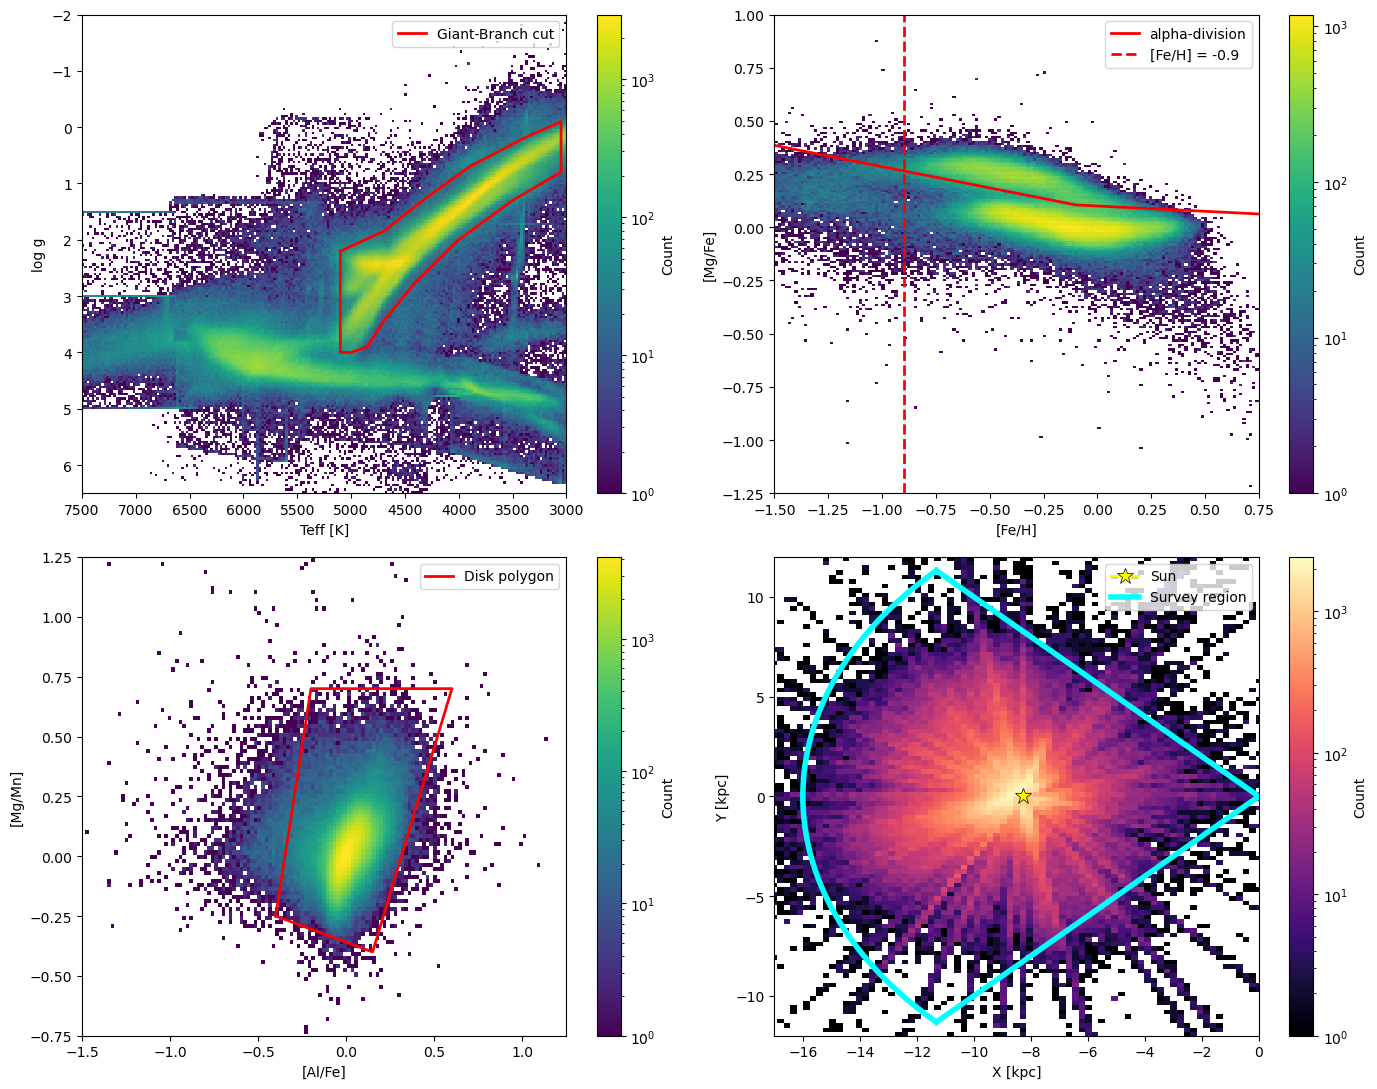

In [64]:
from src.utils import col_to_float_array
t_sel_gb = t[master_mask]
# [Fe/H] and [Mg/Fe] for the giant-branch-only sample (before the low-alpha + metallicity cuts)
fe_gb = col_to_float_array(t_sel_gb, "fe_h")
mgh_gb = col_to_float_array(t_sel_gb, "mg_h")
mgfe_gb = mgh_gb - fe_gb

import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm
from src.config import GB_VERTICES
from src.chemistry import mgfe_dividing_line, FEH_CUT

# pre-chemistry arrays for panel 2
fe_prechem = np.asarray(sel_arrays["feh"], float)
mgfe_prechem = np.asarray(sel_arrays["mgh"], float) - fe_prechem
finite_prechem = np.isfinite(fe_prechem) & np.isfinite(mgfe_prechem)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# ============================================================
# PANEL 1 (top left): Kiel diagram
# ============================================================
ax = axes[0, 0]
finite_basic = np.isfinite(sel_arrays["teff"]) & np.isfinite(sel_arrays["logg"])
x_all = np.asarray(sel_arrays["teff"], float)[finite_basic]
y_all = np.asarray(sel_arrays["logg"], float)[finite_basic]

h1 = ax.hist2d(
    x_all, y_all,
    bins=200,
    range=[(3000, 7500), (-2, 6.5)],
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h1[3], ax=ax, label="Count")

gb_closed = np.vstack([GB_VERTICES, GB_VERTICES[0]])
ax.plot(gb_closed[:, 0], gb_closed[:, 1], "r-", lw=2, label="Giant-Branch cut")
ax.fill(gb_closed[:, 0], gb_closed[:, 1], color="red", alpha=0.06)

ax.invert_xaxis()
ax.invert_yaxis()
ax.set_xlim(7500, 3000)
ax.set_ylim(6.5, -2)
ax.set_xlabel("Teff [K]")
ax.set_ylabel("log g")
ax.legend(loc="upper right")

# ============================================================
# PANEL 2 (top right): [Mg/Fe] vs [Fe/H] -- all giant branch stars
# ============================================================
ax = axes[0, 1]
h2 = ax.hist2d(
    fe_gb, mgfe_gb,
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h2[3], ax=ax, label="Count")

fe_grid = np.linspace(np.nanmin(fe_gb), np.nanmax(fe_gb), 400)
ax.plot(fe_grid, mgfe_dividing_line(fe_grid), color="red", lw=2, label="alpha-division")
ax.axvline(feh_min_extra, color="red", lw=2, ls="--", label=f"[Fe/H] = {feh_min_extra}")
ax.set_xlabel("[Fe/H]")
ax.set_ylabel("[Mg/Fe]")
ax.legend(loc="upper right")
ax.set_xlim(-1.5, 0.75)
ax.set_ylim(-1.25, 1.0)

# ============================================================
# PANEL 3 (bottom left): [Al/Fe] vs [Mg/Mn]
# ============================================================
ax = axes[1, 0]
h3 = ax.hist2d(
    final_arrays["x_finite"],
    final_arrays["y_finite"],
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h3[3], ax=ax, label="Count")

poly = np.vstack([final_arrays["poly_vertices"], final_arrays["poly_vertices"][0]])
ax.plot(poly[:, 0], poly[:, 1], "r-", lw=2, label="Disk polygon")
ax.set_xlabel("[Al/Fe]")
ax.set_ylabel("[Mg/Mn]")
ax.legend(loc="upper right")
ax.set_xlim(-1.5, 1.25)
ax.set_ylim(-0.75, 1.25)

# ============================================================
# PANEL 4 (bottom right): XY density with wedge overlay
# ============================================================
ax = axes[1, 1]
h0 = ax.hist2d(X, Y, bins=200, cmap="magma", norm=mcolors.LogNorm())
fig.colorbar(h0[3], ax=ax, label="Count")

# sun marker
ax.plot(-8.275, 0, marker="*", color="yellow", markersize=12,
        markeredgecolor="k", markeredgewidth=0.5, label="Sun", zorder=5)

# wedge outline
theta_min_wed = 2.35619449
theta_max_wed = 3.92699082
R_min = 0
R_max = 16.0
theta_arc = np.linspace(theta_min_wed, theta_max_wed, 200)
ax.plot(R_min * np.cos(theta_arc), R_min * np.sin(theta_arc), color="cyan", lw=4)
ax.plot(R_max * np.cos(theta_arc), R_max * np.sin(theta_arc), color="cyan", lw=4)
ax.plot([R_min * np.cos(theta_min_wed), R_max * np.cos(theta_min_wed)],
        [R_min * np.sin(theta_min_wed), R_max * np.sin(theta_min_wed)], color="cyan", lw=4)
ax.plot([R_min * np.cos(theta_max_wed), R_max * np.cos(theta_max_wed)],
        [R_min * np.sin(theta_max_wed), R_max * np.sin(theta_max_wed)], color="cyan", lw=4,
        label="Survey region")
ax.set_xlabel("X [kpc]")
ax.set_ylabel("Y [kpc]")
ax.set_xlim(-17, 0)
ax.set_ylim(-12, 12)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

## 4. Binning / fit settings

In [67]:
# shared binning + fitting settings
z_edges    = np.linspace(-3.0, 3.0, 181)
mgfe_edges = np.linspace(-0.2, 0.6, 161)
R_edges    = np.arange(0.5, 15.5 + 0.5, 0.5)

minN_seg_total   = 15
min_bin_count    = 5
min_bins_for_fit = 8
z_fit_min, z_fit_max = -1.5, 1.5
zlim = 0.6

R_centers = 0.5 * (R_edges[:-1] + R_edges[1:])

State ready: `t_final`, `star_pack`, `R_star`, `Z_star`, `phi_star`, `mgfe_star`,
`t_star`, `e_mg_h_star`, `e_fe_h_star`, `mgfe_err_star`, `segm`, `crowd_bounds`,
`seg_diag`, `SEG_PLOT`, `SEG_PLOT_heat`, plus the binning settings.

## 5. sech² mixture model

Two-component sech² dip in [Mg/Fe] vs z, with a HalfNormal-parameterized amplitude
(forced negative), an outlier-mixture likelihood (`Q` = outlier fraction), and priors
tuned to the physical scale of the problem (dip depth ~0.05-0.15 dex, z0 within
~0.2 kpc of the plane, thin/thick-disk-like scale heights).

In [68]:
def mixture_of_sech2(z, A1, A2, h1, h2, z0):
    dz = z - z0
    return A1 * (1 / jnp.cosh(dz / h1)) ** 2 + A2 * (1 / jnp.cosh(dz / h2)) ** 2

In [69]:
def model(data):
    _A1 = numpyro.sample("_A1", dist.HalfNormal(0.2))
    _A2 = numpyro.sample("_A2", dist.HalfNormal(0.2))
    A1 = numpyro.deterministic("A1", -_A1)
    A2 = numpyro.deterministic("A2", -_A2)

    h1   = numpyro.sample("h1",   dist.Uniform(0.04, 1.0))
    d_h2 = numpyro.sample("d_h2", dist.Uniform(0.04, 0.5))
    h2 = numpyro.deterministic("h2", h1 + d_h2)

    z0 = numpyro.sample("z0", dist.Normal(0.0, 0.2))

    offset = numpyro.sample("offset", dist.Normal(0.05, 0.10))

    model_y = mixture_of_sech2(data["z"], A1, A2, h1, h2, z0) + offset

    Q = numpyro.sample("Q", dist.TruncatedNormal(0.0, 0.05, low=0, high=1.0))
    mix = dist.Categorical(probs=jnp.array([Q, 1.0 - Q]))
    components = [
        dist.Normal(0.0, jnp.sqrt(1.0**2 + data["mg_fe_err"]**2)),
        dist.Normal(model_y, data["mg_fe_err"]),
    ]

    numpyro.sample(
        "obs",
        dist.Mixture(mix, components),
        obs=data["mg_fe"],
    )

## 6. Binning + per-cell fit helpers

`bin_one` bins [Mg/Fe] vs z with inverse-variance weighting plus intrinsic-scatter
inflation. `fit_sech2` runs NUTS (`dense_mass=True`, `target_accept_prob=0.95`,
`init_to_median`) for 1000 warmup / 1000 samples / 2 chains. `select_annulus_segment`
pulls stars for one (R, segment) cell, bins them, and applies the min-count / min-bins
cuts before handing off to the fit.

In [70]:
Z_BINS_FIT = np.arange(-5, 5 + 1e-3, 0.1)


def bin_one(z, mgfe, mgfe_err, z_bins=Z_BINS_FIT):
    """Weighted mean + intrinsic-scatter-inflated error, binned in z."""
    stat1 = binned_statistic(z, mgfe / mgfe_err**2, bins=z_bins, statistic="sum")
    stat2 = binned_statistic(z, 1 / mgfe_err**2, bins=z_bins, statistic="sum")
    stat_std = binned_statistic(z, mgfe, bins=z_bins, statistic="std")
    stat_count = binned_statistic(z, mgfe, bins=z_bins, statistic="count")

    intrinsic_scatter = stat_std.statistic / np.sqrt(stat_count.statistic)

    mean_mg_fe = stat1.statistic / stat2.statistic
    mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
    z_binc = 0.5 * (z_bins[1:] + z_bins[:-1])

    counts = stat_count.statistic
    return z_binc, mean_mg_fe, mean_mg_fe_err, counts


def fit_sech2(z_binc, mean_mg_fe, mean_mg_fe_err, key,
              num_warmup=1000, num_samples=1000, num_chains=2,
              progress_bar=False):
    sampler = infer.MCMC(
        infer.NUTS(
            model,
            dense_mass=True,
            target_accept_prob=0.95,
            init_strategy=infer.init_to_median(num_samples=20),
        ),
        num_warmup=num_warmup, num_samples=num_samples,
        num_chains=num_chains, progress_bar=progress_bar,
    )
    data = {
        "z": jnp.asarray(z_binc),
        "mg_fe": jnp.asarray(mean_mg_fe),
        "mg_fe_err": jnp.asarray(mean_mg_fe_err),
    }
    sampler.run(key, data=data)
    return sampler


def select_annulus_segment(R_use, Z_use, mgfe_use, mgfe_err_use, seg_mask,
                           Rmin, Rmax,
                           min_bin_count=min_bin_count,
                           min_bins_for_fit=min_bins_for_fit,
                           z_fit_min=z_fit_min, z_fit_max=z_fit_max):
    """Select stars, bin, return data ready for MCMC.

    Returns (z_binc, mean_mg_fe, mean_mg_fe_err, n_stars, ok); ok is False if the
    (annulus, segment) doesn't have enough data to fit.
    """
    m = (
        seg_mask
        & (R_use >= Rmin) & (R_use < Rmax)
        & np.isfinite(Z_use) & np.isfinite(mgfe_use)
        & np.isfinite(mgfe_err_use) & (mgfe_err_use > 0)
    )
    n_stars = int(m.sum())
    if n_stars < minN_seg_total:
        return None, None, None, n_stars, False

    z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(
        Z_use[m], mgfe_use[m], mgfe_err_use[m]
    )

    good = (
        np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
        & (counts >= min_bin_count)
        & (z_binc >= z_fit_min) & (z_binc <= z_fit_max)
    )
    if good.sum() < min_bins_for_fit:
        return None, None, None, n_stars, False

    return (
        np.asarray(z_binc[good], float),
        np.asarray(mean_mg_fe[good], float),
        np.asarray(mean_mg_fe_err[good], float),
        n_stars,
        True,
    )

## 7. MCMC over (annulus, segment) grid → z₀

Fits every (R, crowded-segment) cell. Loads `sech2_mcmc_results2.pkl` if present;
set `FORCE_RERUN = True` to redo the loop from scratch. This is many fits — after
the first JIT-compiles (~30 s), subsequent fits are a few seconds each.

In [71]:
RESULTS_PATH = "sech2_mcmc_results2.pkl"
FORCE_RERUN  = False    # set True to re-run the loop from scratch

if os.path.exists(RESULTS_PATH) and not FORCE_RERUN:
    with open(RESULTS_PATH, "rb") as f:
        saved = pickle.load(f)
    z0_med   = saved["z0_med"]
    z0_std   = saved["z0_std"]
    n_stars  = saved["n_stars"]
    n_bins   = saved["n_bins"]
    ok_grid  = saved["ok_grid"]
    per_cell = saved["per_cell"]
    print(f"loaded results from {RESULTS_PATH}  "
          f"({int(ok_grid.sum())}/{ok_grid.size} cells)")
else:
    n_R   = len(R_edges) - 1
    n_seg = len(SEG_PLOT_heat)
    z0_med  = np.full((n_R, n_seg), np.nan)
    z0_std  = np.full((n_R, n_seg), np.nan)
    n_stars = np.zeros((n_R, n_seg), dtype=int)
    n_bins  = np.zeros((n_R, n_seg), dtype=int)
    ok_grid = np.zeros((n_R, n_seg), dtype=bool)
    per_cell = {}   # (i_R, j_seg) -> dict with binned data + samples

    key   = jr.PRNGKey(0)
    pairs = list(product(range(n_R), range(n_seg)))

    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin = float(R_edges[i_R]); Rmax = float(R_edges[i_R + 1])
        seg_id = SEG_PLOT_heat[j_seg]
        z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment(
            R_star, Z_star, mgfe_star, mgfe_err_star,
            seg_mask=segm[seg_id], Rmin=Rmin, Rmax=Rmax,
        )
        n_stars[i_R, j_seg] = ns_k
        if not ok_k:
            continue
        n_bins[i_R, j_seg] = len(z_binc_k)
        try:
            key, sub = jr.split(key)
            sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
            samples_k = sampler_k.get_samples()
            z0_med[i_R, j_seg] = float(np.median(samples_k["z0"]))
            z0_std[i_R, j_seg] = float(np.std(samples_k["z0"]))
            ok_grid[i_R, j_seg] = True
            per_cell[(i_R, j_seg)] = {
                "z_binc": np.asarray(z_binc_k),
                "mean":   np.asarray(mean_k),
                "err":    np.asarray(err_k),
                "samples": {kk: np.asarray(vv[:1000]) for kk, vv in samples_k.items()},
            }
        except Exception as e:
            print(f"  fit failed: seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 10 == 0 or k == len(pairs):
            print(f"  done {k}/{len(pairs)}", flush=True)

    print("fits complete:", int(ok_grid.sum()), "/", ok_grid.size)

    with open(RESULTS_PATH, "wb") as f:
        pickle.dump({
            "z0_med":   z0_med,
            "z0_std":   z0_std,
            "n_stars":  n_stars,
            "n_bins":   n_bins,
            "ok_grid":  ok_grid,
            "per_cell": per_cell,
            "R_edges":       R_edges,
            "SEG_PLOT_heat": SEG_PLOT_heat,
            "crowd_bounds":  np.asarray(crowd_bounds),
        }, f)
    print(f"saved to {RESULTS_PATH}")

n_R   = len(R_edges) - 1
n_seg = len(SEG_PLOT_heat)

loaded results from sech2_mcmc_results2.pkl  (206/330 cells)


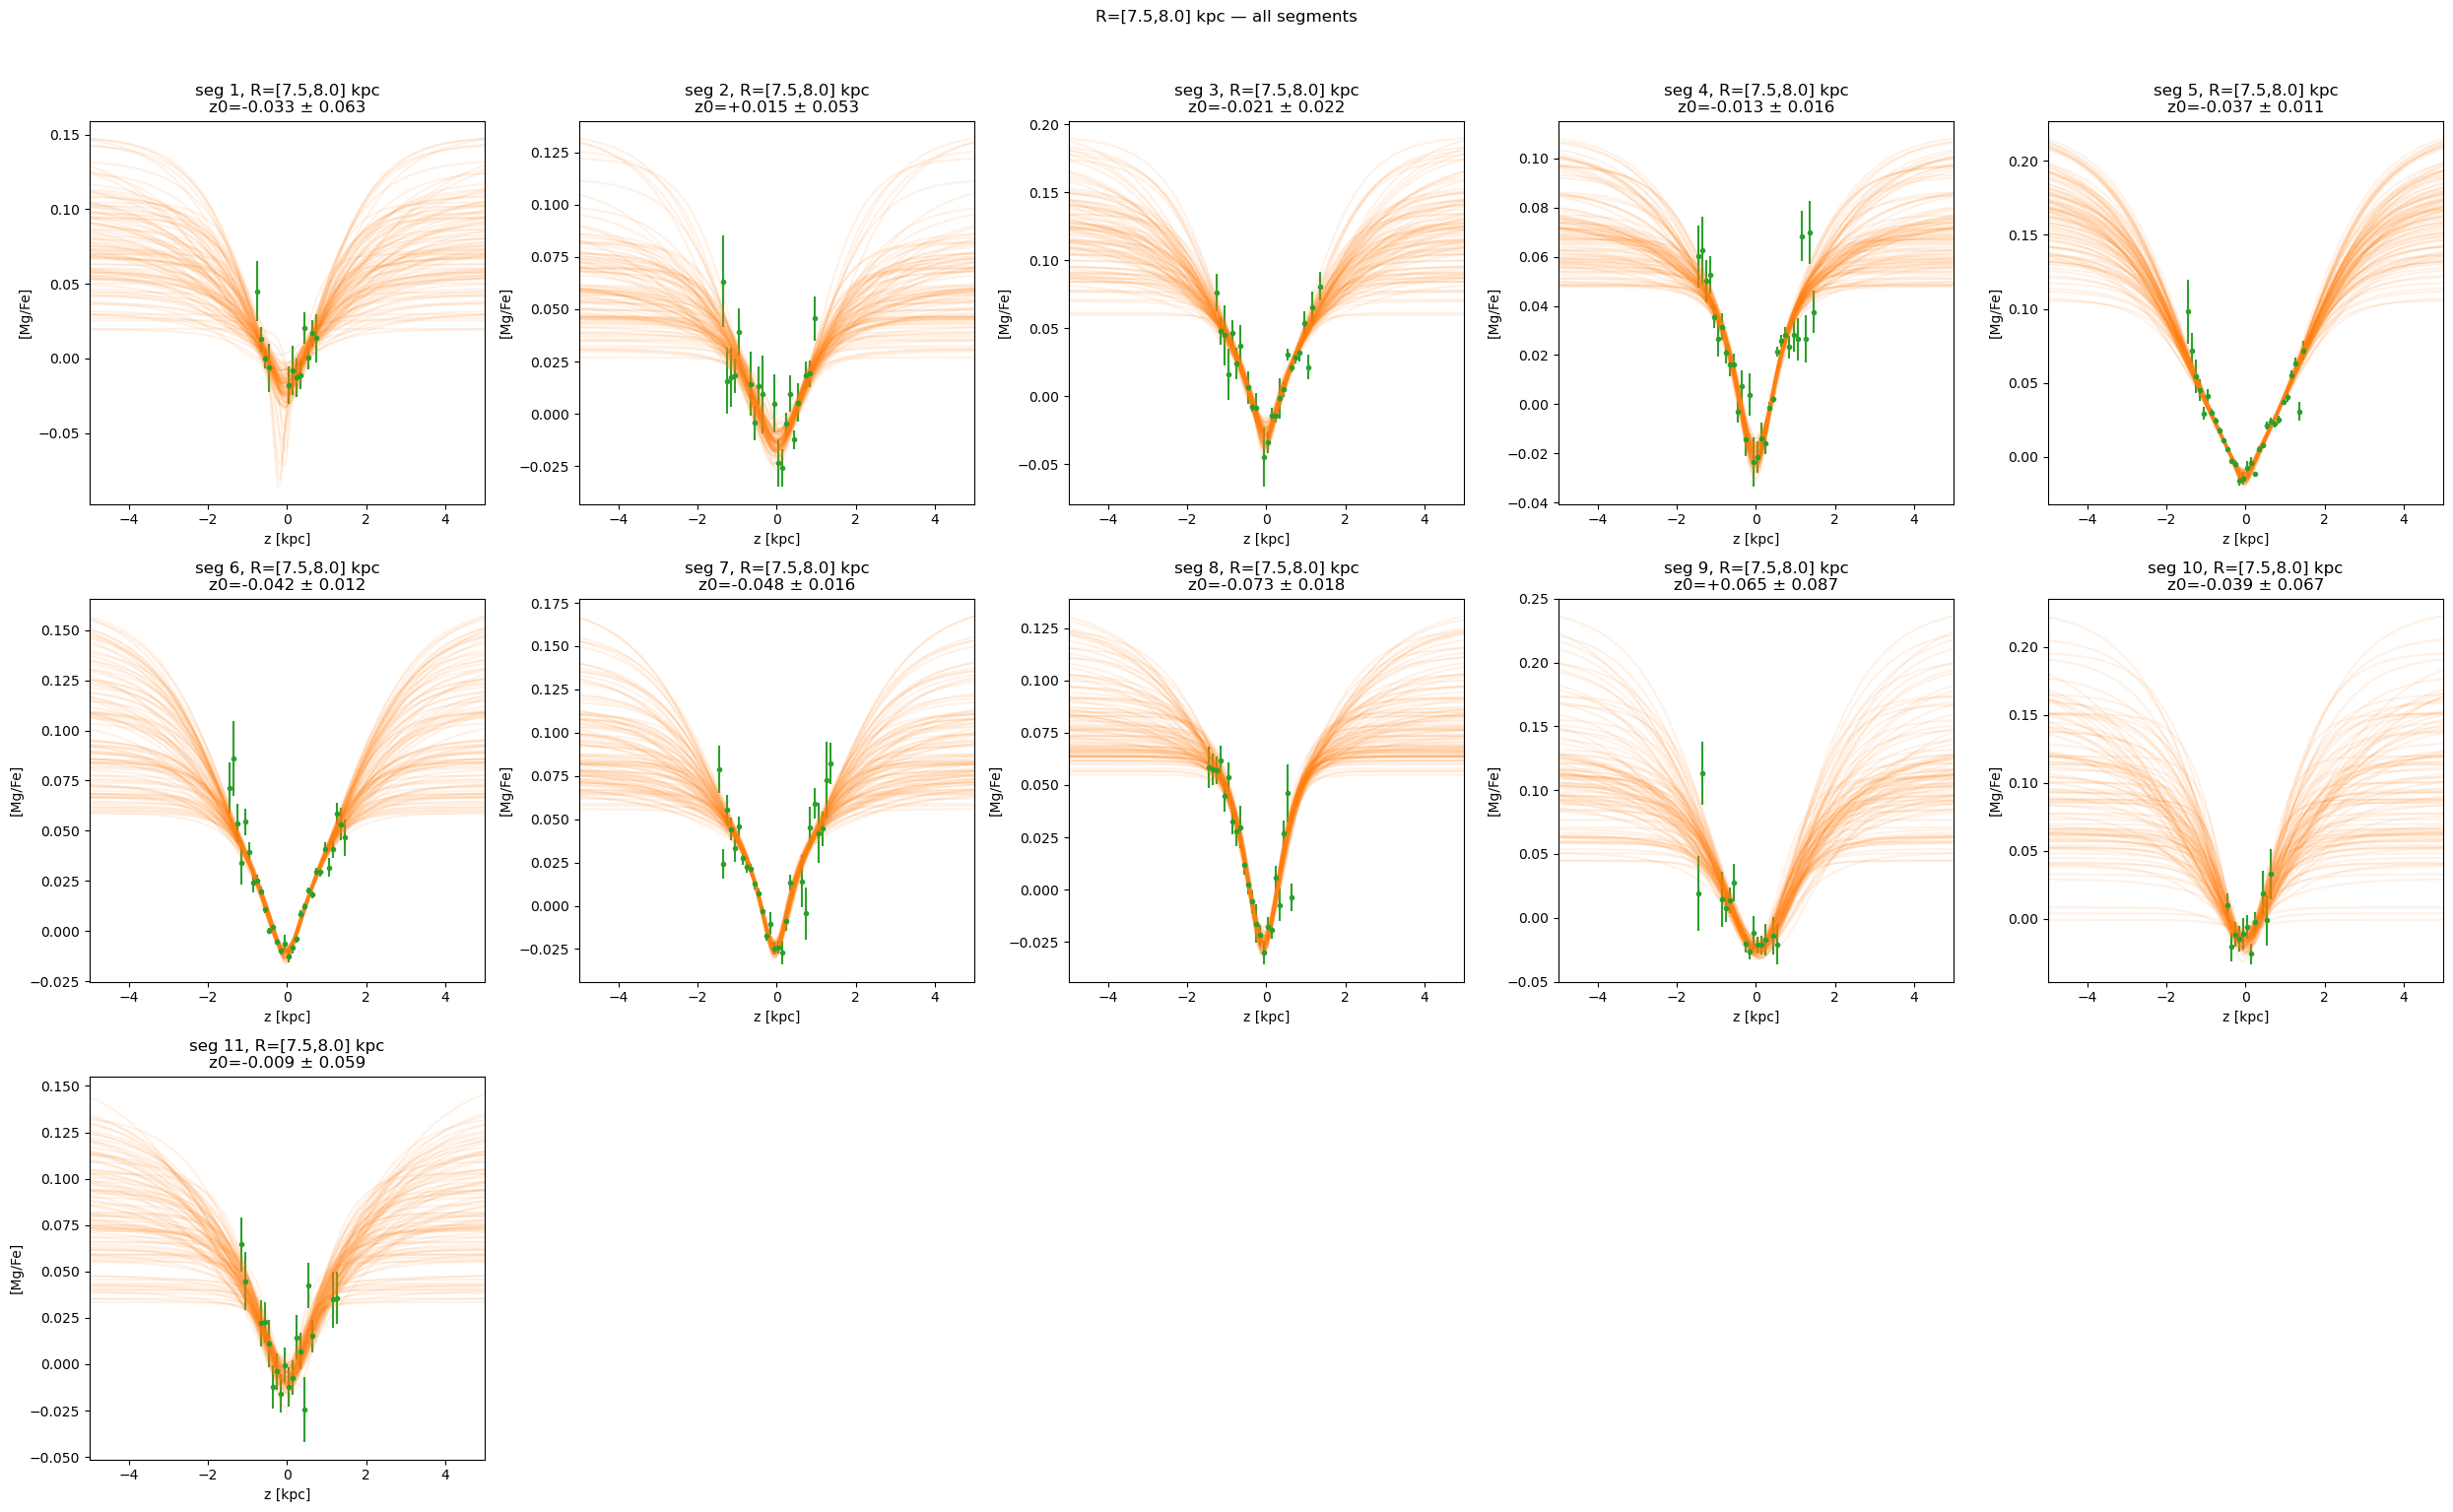

In [72]:
i_R_focus = np.searchsorted(R_edges, 7.5)  
cells_in_R = [(i_R, j_seg) for (i_R, j_seg) in per_cell.keys() if i_R == i_R_focus]
n_cells = len(cells_in_R)
n_cols = 5
n_rows = int(np.ceil(n_cells / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), squeeze=False)
z_grid = np.linspace(-5, 5, 200)

for idx, (i_R, j_seg) in enumerate(cells_in_R):
    r, c = divmod(idx, n_cols)
    ax = axes[r, c]
    cell = per_cell[(i_R, j_seg)]
    seg_id = SEG_PLOT_heat[j_seg]
    s = cell["samples"]

    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                color="C2", linestyle="", marker=".", label="binned mean")

    for i in range(min(100, len(s["A1"]))):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        y_pred = mixture_of_sech2(z_grid, cell_sample["A1"], cell_sample["A2"],
                                  cell_sample["h1"], cell_sample["h2"],
                                  cell_sample["z0"]) + cell_sample["offset"]
        ax.plot(z_grid, y_pred, color="C1", alpha=0.1)

    ax.set_xlabel("z [kpc]")
    ax.set_ylabel("[Mg/Fe]")
    ax.set_title(f"seg {seg_id}, R=[{R_edges[i_R]:.1f},{R_edges[i_R+1]:.1f}] kpc\n"
                 f"z0={z0_med[i_R,j_seg]:+.3f} \u00b1 {z0_std[i_R,j_seg]:.3f}")
    ax.set_xlim(-5, 5)

for idx in range(n_cells, n_rows * n_cols):
    r, c = divmod(idx, n_cols)
    axes[r, c].axis("off")

plt.suptitle(f"R=[{R_edges[i_R_focus]:.1f},{R_edges[i_R_focus+1]:.1f}] kpc \u2014 all segments", y=1.02)
plt.tight_layout()
plt.show()

## 8. Polar heatmaps

Build `theta_edges` from `crowd_bounds`, then plot z₀ (median + stddev) as a polar
`pcolormesh` over (R, θ), with the Sun marked. Followed by the same treatment for
h₁, h₂, Q (outlier fraction), and the A1/A2 amplitude ratio.

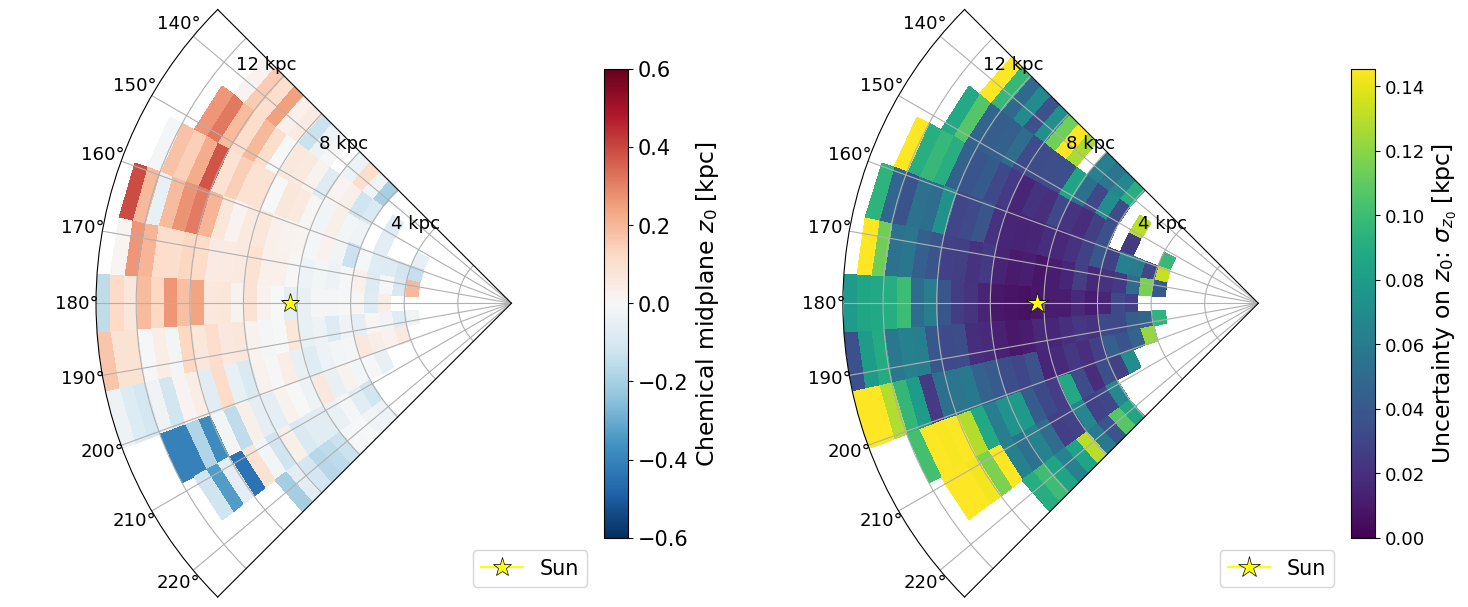

In [73]:
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi
assert len(theta_edges) - 1 == n_seg, "theta_edges length must match number of crowded segments"

T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
Zmap_med = np.ma.masked_invalid(z0_med)
Zmap_std = np.ma.masked_invalid(z0_std)
std_max = float(np.nanpercentile(z0_std[np.isfinite(z0_std)], 95)) if np.isfinite(z0_std).any() else 1.0
theta_min = theta_edges[0]
theta_max = theta_edges[-1]
theta_sun = np.radians(180)  # Sun at phi=180 in Galactocentric convention
R_sun = 8.275

fig = plt.figure(figsize=(15, 7))

# left: z0 median
ax1 = plt.subplot(1, 2, 1, projection="polar")
pcm1 = ax1.pcolormesh(T_mesh, R_mesh, Zmap_med, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
cb1 = fig.colorbar(pcm1, ax=ax1, pad=0.01, shrink=0.7)
cb1.set_label(r"Chemical midplane $z_0$ [kpc]", fontsize=17)
cb1.ax.tick_params(labelsize=15)
ax1.tick_params(labelsize=13)
ax1.set_theta_zero_location("E")
ax1.set_theta_direction(1)
ax1.set_rmax(R_edges[-1])
ax1.set_thetamin(np.degrees(theta_min))
ax1.set_thetamax(np.degrees(theta_max))
ax1.set_title("")
for r in R_edges[R_edges % 4 == 0]:
    ax1.text(theta_min - np.radians(3), r, f"{r:.0f} kpc",
             fontsize=13, ha="right", va="center")
ax1.set_yticklabels([])
ax1.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14,
         markeredgecolor="k", markeredgewidth=0.5, zorder=5, label="Sun")
ax1.legend(loc="lower right", fontsize=15)

# right: z0 stddev
ax2 = plt.subplot(1, 2, 2, projection="polar")
pcm2 = ax2.pcolormesh(T_mesh, R_mesh, Zmap_std, cmap="viridis",
                      vmin=0.0, vmax=std_max, shading="flat")
cb2 = fig.colorbar(pcm2, ax=ax2, pad=0.01, shrink=0.7)
cb2.set_label(r"Uncertainty on $z_0$: $\sigma_{z_0}$ [kpc]", fontsize=17)
cb2.ax.tick_params(labelsize=13)
ax2.set_theta_zero_location("E")
ax2.set_theta_direction(1)
ax2.tick_params(labelsize=13)
ax2.set_rmax(R_edges[-1])
ax2.set_thetamin(np.degrees(theta_min))
ax2.set_thetamax(np.degrees(theta_max))
ax2.set_title("")
for r in R_edges[R_edges % 4 == 0]:
    ax2.text(theta_min - np.radians(3), r, f"{r:.0f} kpc",
             fontsize=13, ha="right", va="center")
ax2.set_yticklabels([])
ax2.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=16,
         markeredgecolor="k", markeredgewidth=0.5, zorder=5, label="Sun")
ax2.legend(loc="lower right", fontsize=15)

plt.tight_layout()
plt.show()

In [74]:
def collect_stats(varname):
    """Pull a variable's samples from every cell in per_cell, return (med, std) grids."""
    med = np.full((n_R, n_seg), np.nan)
    std = np.full((n_R, n_seg), np.nan)
    for (i_R, j_seg), cell in per_cell.items():
        s = cell["samples"]
        if varname in s:
            med[i_R, j_seg] = float(np.median(s[varname]))
            std[i_R, j_seg] = float(np.std(s[varname]))
    return med, std

h1_med, h1_std = collect_stats("h1")
Q_med,  Q_std  = collect_stats("Q")
A1_med, A1_std = collect_stats("A1")
A2_med, A2_std = collect_stats("A2")
Aratio_med = A1_med / A2_med
Aratio_std = Aratio_med * np.sqrt((A1_std / A1_med)**2 + (A2_std / A2_med)**2)  # TODO: double check error propagation

# h2 = h1 + d_h2 -- compute from samples
h2_med = np.full((n_R, n_seg), np.nan)
h2_std = np.full((n_R, n_seg), np.nan)
for (i_R, j_seg), cell in per_cell.items():
    s = cell["samples"]
    if "h1" in s and "d_h2" in s:
        h2_samples = np.asarray(s["h1"]) + np.asarray(s["d_h2"])
        h2_med[i_R, j_seg] = float(np.median(h2_samples))
        h2_std[i_R, j_seg] = float(np.std(h2_samples))

print("collected.  Q present:", np.isfinite(Q_med).any())

collected.  Q present: True


## 9. Flare: radial-only bins → h_eff vs R

Same fit machinery (`bin_one` + `fit_sech2`), but binning stars in radial annuli
only (ignoring segment/φ) to study h_eff vs R across the full disk. Bins are
1.0 kpc wide, and overlap by 0.5 kpc.

In [75]:
from tqdm import tqdm
import jax
import jax.random as jr

R_centers_flare = np.arange(4, 15+1e-3, 0.5)
R_width = 1.0
n_R_flare = len(R_centers_flare)

R_arr     = np.asarray(R_star)
Z_arr     = np.asarray(Z_star)
mgfe_arr  = np.asarray(mgfe_star)
err_arr   = np.asarray(mgfe_err_star)

m_base = (
    np.isfinite(R_arr) & np.isfinite(Z_arr)
    & np.isfinite(mgfe_arr) & np.isfinite(err_arr)
    & (err_arr > 0)
)

# store results
per_R_flare = {}
key = jr.PRNGKey(0)

for i_R in tqdm(range(n_R_flare), desc="fitting radial bins"):
    Rlo = R_centers_flare[i_R] - R_width / 2
    Rhi = R_centers_flare[i_R] + R_width / 2

    m = m_base & (R_arr >= Rlo) & (R_arr < Rhi)
    n_stars = int(m.sum())

    if n_stars < minN_seg_total:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: skipping, only {n_stars} stars")
        continue

    z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(
        Z_arr[m], mgfe_arr[m], err_arr[m]
    )

    good = (
        np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
        & (counts >= min_bin_count)
        & (z_binc >= z_fit_min) & (z_binc <= z_fit_max)
    )

    if good.sum() < min_bins_for_fit:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: skipping, only {good.sum()} good bins")
        continue

    try:
        key, sub = jr.split(key)
        sampler = fit_sech2(
            np.asarray(z_binc[good], float),
            np.asarray(mean_mg_fe[good], float),
            np.asarray(mean_mg_fe_err[good], float),
            sub,
            progress_bar=False
        )
        samples = sampler.get_samples()
        per_R_flare[i_R] = {
            "Rlo": Rlo, "Rhi": Rhi,
            "n_stars": n_stars,
            "z_binc": np.asarray(z_binc[good]),
            "mean": np.asarray(mean_mg_fe[good]),
            "err": np.asarray(mean_mg_fe_err[good]),
            "samples": {k: np.asarray(v) for k, v in samples.items()},
        }
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit ok, n_stars={n_stars}")
    except Exception as e:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit failed -> {e}")

print(f"fits complete: {len(per_R_flare)}/{n_R_flare}")

import pickle

# save
with open("per_R_flare5.pkl", "wb") as f:
    pickle.dump(per_R_flare, f)

fitting radial bins:   0%|                               | 0/23 [00:00<?, ?it/s]/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:13: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:14: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:24: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
fitting radial bins:   4%|█                      | 1/23 [00:16<06:10, 16.84s/it]

R=[3.5,4.5]: fit ok, n_stars=1978


fitting radial bins:   9%|██                     | 2/23 [00:23<03:48, 10.88s/it]

R=[4.0,5.0]: fit ok, n_stars=2857


fitting radial bins:  13%|███                    | 3/23 [00:30<02:59,  8.95s/it]

...

R=[13.5,14.5]: fit ok, n_stars=5968


fitting radial bins:  96%|█████████████████████ | 22/23 [05:48<00:13, 13.21s/it]

R=[14.0,15.0]: fit ok, n_stars=3901


fitting radial bins: 100%|██████████████████████| 23/23 [05:56<00:00, 15.52s/it]

R=[14.5,15.5]: fit ok, n_stars=2516
fits complete: 23/23


loaded 23 radial bins


computing h_eff: 100%|██████████████████████████| 23/23 [00:08<00:00,  2.57it/s]


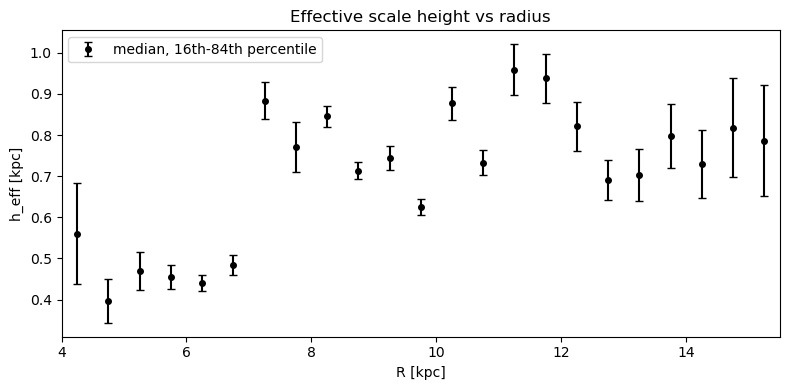

In [92]:
import pickle
import numpy as np
from scipy.optimize import brentq

# reload saved results
with open("per_R_flare5.pkl", "rb") as f:
    per_R_flare = pickle.load(f)
print(f"loaded {len(per_R_flare)} radial bins")

R_edges_flare = np.arange(4, 16, 0.5)
n_R_flare = len(R_edges_flare) - 1
R_centers_flare = 0.5 * (R_edges_flare[:-1] + R_edges_flare[1:])

def root_func(z, pars):
    Ystar = mixture_of_sech2(
        z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], pars["z0"]
    )
    return Ystar - 0.5 * (pars["A1"] + pars["A2"])

h_eff_med_flare = np.full(n_R_flare, np.nan)
h_eff_std_flare = np.full(n_R_flare, np.nan)

for i_R, cell in tqdm(per_R_flare.items(), desc="computing h_eff"):
    s = cell["samples"]

    h_effs = []
    for i in range(256):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        hi = 8 * max(cell_sample["h1"], cell_sample["h2"])
        try:
            zstar = brentq(root_func, cell_sample["z0"] + 1e-9, hi, args=(cell_sample,))
            h_effs.append(zstar - cell_sample["z0"])
        except ValueError:
            continue

    if len(h_effs) > 0:
        h_effs = np.array(h_effs)
        h_eff_med_flare[i_R] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std_flare[i_R] = 0.5 * (pcl[1] - pcl[0])

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers_flare, h_eff_med_flare, yerr=h_eff_std_flare,
            fmt="o", color="k", ms=4, capsize=3,
            label="median, 16th-84th percentile")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel("h_eff [kpc]")
ax.set_title("Effective scale height vs radius")
ax.set_xlim(R_edges_flare[0], R_edges_flare[-1])
plt.tight_layout()
plt.show()

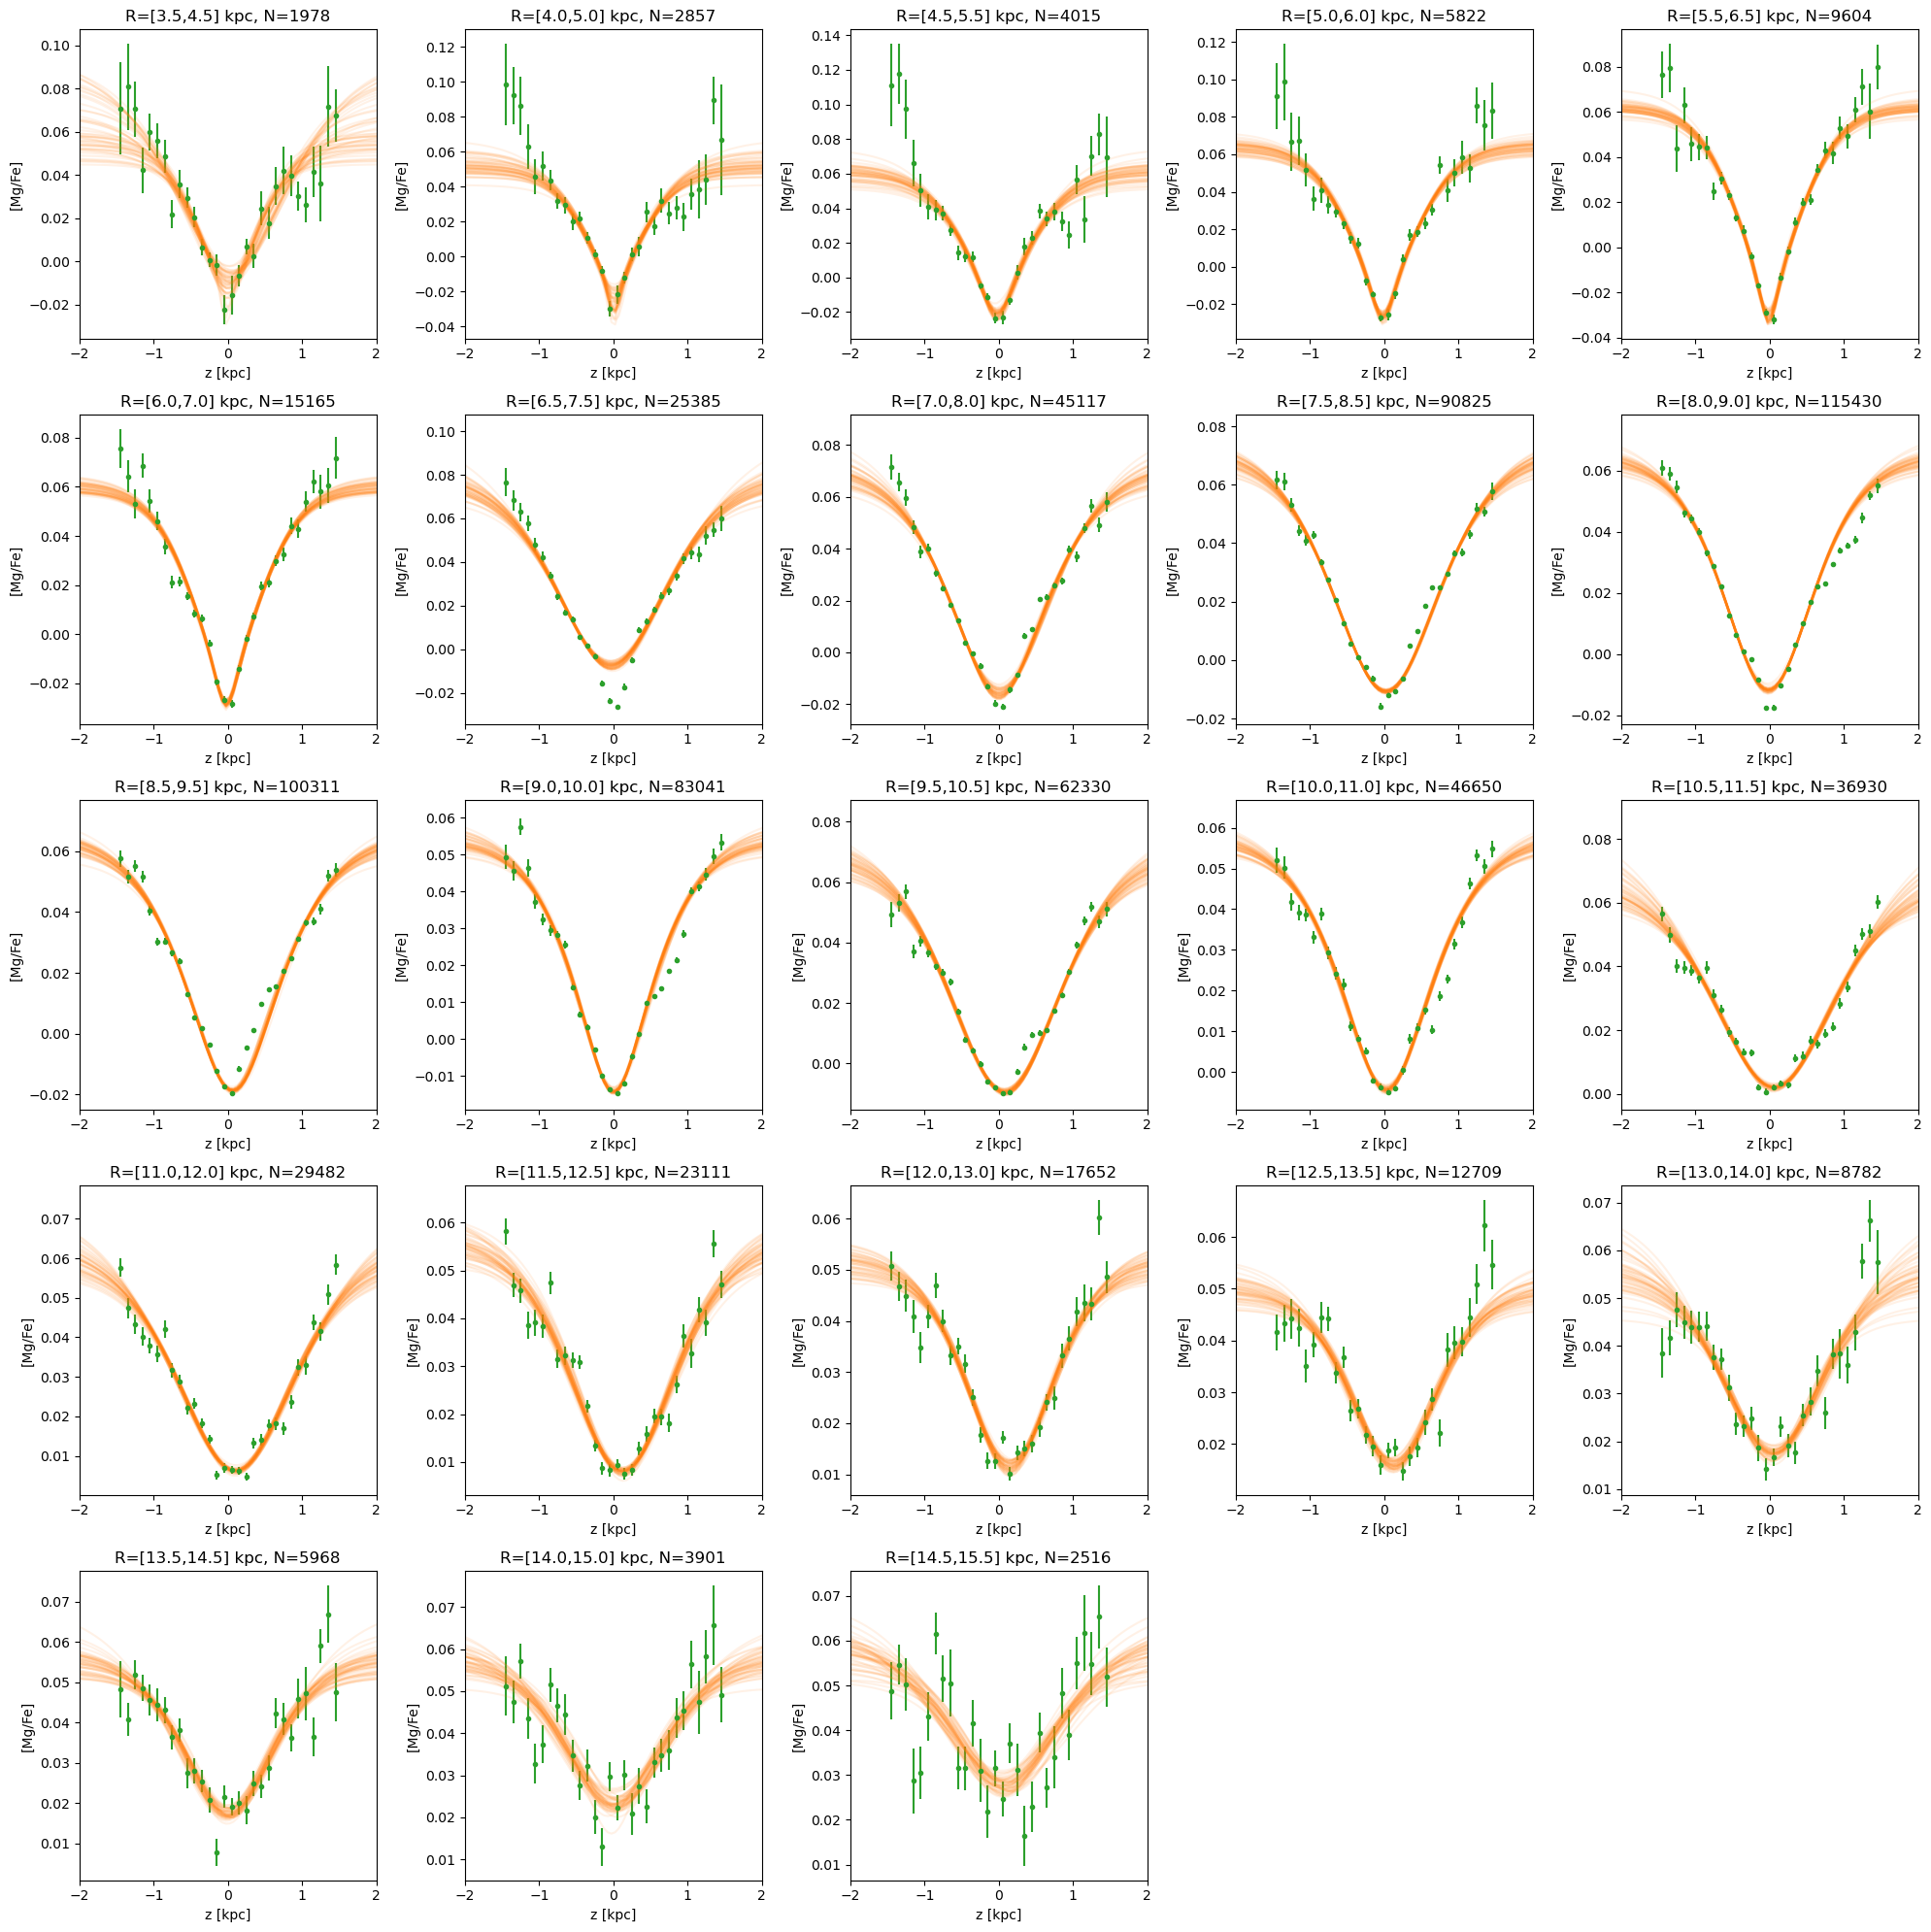

In [77]:
# Diagnostic: model fit + binned data for every radial bin (sanity check)
z_grid = np.linspace(-5, 5, 200)
n_cols = 5
n_rows = int(np.ceil(len(per_R_flare) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), squeeze=False)

for idx, (i_R, cell) in enumerate(per_R_flare.items()):
    r, c = divmod(idx, n_cols)
    ax = axes[r, c]
    s = cell["samples"]

    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                color="C2", linestyle="", marker=".")

    for i in range(min(50, len(s["A1"]))):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        y_pred = mixture_of_sech2(z_grid, cell_sample["A1"], cell_sample["A2"],
                                  cell_sample["h1"], cell_sample["h2"],
                                  cell_sample["z0"]) + cell_sample["offset"]
        ax.plot(z_grid, y_pred, color="C1", alpha=0.1)

    ax.set_xlabel("z [kpc]")
    ax.set_ylabel("[Mg/Fe]")
    ax.set_title(f"R=[{cell['Rlo']:.1f},{cell['Rhi']:.1f}] kpc, N={cell['n_stars']}")
    ax.set_xlim(-2, 2)

for idx in range(len(per_R_flare), n_rows * n_cols):
    r, c = divmod(idx, n_cols)
    axes[r, c].axis("off")

plt.tight_layout()
plt.show()

## Age Bins

In [78]:
# build an age array aligned with t_final (NaN where there's no valid match)
age_col_t4 = np.asarray(t4["AgeJTsketchy"], float).ravel()
t4_sdss_id = np.asarray(t4["sdss_id"])

# only trust ages in the sane range established earlier (0-15 Gyr)
valid_age_mask_t4 = np.isfinite(age_col_t4) & (age_col_t4 >= 0) & (age_col_t4 <= 15)
t4_sdss_id_valid = t4_sdss_id[valid_age_mask_t4]
age_valid = age_col_t4[valid_age_mask_t4]

# lookup dict: sdss_id -> age (only valid ages included)
id_to_age_t4 = dict(zip(t4_sdss_id_valid, age_valid))

final_sdss_id = np.asarray(t_final["sdss_id"])
t_final_age = np.array([id_to_age_t4.get(sid, np.nan) for sid in final_sdss_id])

has_age = np.isfinite(t_final_age)
print(f"t_final stars with a usable age: {has_age.sum()} / {len(t_final)} "
      f"({100*has_age.sum()/len(t_final):.1f}%)")

# three age bins: 0-3, 3-8, 8+
young_mask = has_age & (t_final_age < 3)
mid_mask   = has_age & (t_final_age >= 3) & (t_final_age < 8)
old_mask   = has_age & (t_final_age >= 8)

t_final_young = t_final[young_mask]
t_final_mid   = t_final[mid_mask]
t_final_old   = t_final[old_mask]

print(f"young (0-3 Gyr):  {len(t_final_young)}")
print(f"mid   (3-8 Gyr):  {len(t_final_mid)}")
print(f"old   (8+ Gyr):   {len(t_final_old)}")
print(f"total binned:     {len(t_final_young) + len(t_final_mid) + len(t_final_old)}")
print(f"no valid age:     {(~has_age).sum()}")

t_final stars with a usable age: 352398 / 391384 (90.0%)
young (0-3 Gyr):  72901
mid   (3-8 Gyr):  253719
old   (8+ Gyr):   25778
total binned:     352398
no valid age:     38986


In [79]:
def run_grid_fit(R_use, Z_use, mgfe_use, mgfe_err_use, seg_masks, label, results_path):
    """Same loop as Section 7, but parameterized over which stars to use."""
    n_R = len(R_edges) - 1
    n_seg = len(SEG_PLOT_heat)
    z0_med = np.full((n_R, n_seg), np.nan)
    z0_std = np.full((n_R, n_seg), np.nan)
    n_stars = np.zeros((n_R, n_seg), dtype=int)
    n_bins = np.zeros((n_R, n_seg), dtype=int)
    ok_grid = np.zeros((n_R, n_seg), dtype=bool)
    per_cell = {}

    key = jr.PRNGKey(0)
    pairs = list(product(range(n_R), range(n_seg)))

    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin = float(R_edges[i_R]); Rmax = float(R_edges[i_R + 1])
        seg_id = SEG_PLOT_heat[j_seg]
        # note: seg_masks[seg_id] must already be sized to match R_use/Z_use/etc.
        z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment(
            R_use, Z_use, mgfe_use, mgfe_err_use,
            seg_mask=seg_masks[seg_id], Rmin=Rmin, Rmax=Rmax,
        )
        n_stars[i_R, j_seg] = ns_k
        if not ok_k:
            continue
        n_bins[i_R, j_seg] = len(z_binc_k)
        try:
            key_local, sub = jr.split(key)
            sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
            samples_k = sampler_k.get_samples()
            z0_med[i_R, j_seg] = float(np.median(samples_k["z0"]))
            z0_std[i_R, j_seg] = float(np.std(samples_k["z0"]))
            ok_grid[i_R, j_seg] = True
            per_cell[(i_R, j_seg)] = {
                "z_binc": np.asarray(z_binc_k), "mean": np.asarray(mean_k),
                "err": np.asarray(err_k),
                "samples": {kk: np.asarray(vv[:1000]) for kk, vv in samples_k.items()},
            }
            key = key_local
        except Exception as e:
            print(f"  [{label}] fit failed: seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 20 == 0 or k == len(pairs):
            print(f"  [{label}] done {k}/{len(pairs)}", flush=True)

    print(f"[{label}] fits complete:", int(ok_grid.sum()), "/", ok_grid.size)
    with open(results_path, "wb") as f:
        pickle.dump({"z0_med": z0_med, "z0_std": z0_std, "n_stars": n_stars,
                     "n_bins": n_bins, "ok_grid": ok_grid, "per_cell": per_cell}, f)
    return z0_med, z0_std, per_cell

In [80]:
star_id = np.asarray(t_star["sdss_id"])
star_age = np.array([id_to_age_t4.get(sid, np.nan) for sid in star_id])

young_star_mask = np.isfinite(star_age) & (star_age < 3)
mid_star_mask   = np.isfinite(star_age) & (star_age >= 3) & (star_age < 8)
old_star_mask   = np.isfinite(star_age) & (star_age >= 8)

print(f"young: {young_star_mask.sum()}, mid: {mid_star_mask.sum()}, "
      f"old: {old_star_mask.sum()}, no age: {(~np.isfinite(star_age)).sum()}")

# fit each age bin
z0_med_young, z0_std_young, per_cell_young = run_grid_fit(
    R_star[young_star_mask], Z_star[young_star_mask], mgfe_star[young_star_mask],
    mgfe_err_star[young_star_mask],
    {sid: m[young_star_mask] for sid, m in segm.items()},
    label="young", results_path="sech2_mcmc_results_young.pkl",
)

z0_med_mid, z0_std_mid, per_cell_mid = run_grid_fit(
    R_star[mid_star_mask], Z_star[mid_star_mask], mgfe_star[mid_star_mask],
    mgfe_err_star[mid_star_mask],
    {sid: m[mid_star_mask] for sid, m in segm.items()},
    label="mid", results_path="sech2_mcmc_results_mid.pkl",
)

z0_med_old, z0_std_old, per_cell_old = run_grid_fit(
    R_star[old_star_mask], Z_star[old_star_mask], mgfe_star[old_star_mask],
    mgfe_err_star[old_star_mask],
    {sid: m[old_star_mask] for sid, m in segm.items()},
    label="old", results_path="sech2_mcmc_results_old.pkl",
)

young: 72748, mid: 252024, old: 25750, no age: 38959


/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:13: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:14: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:24: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


  [young] done 160/330
  [young] done 180/330
  [young] done 200/330
  [young] done 240/330
  [young] done 260/330
  [young] done 280/330
[young] fits complete: 100 / 330
  [mid] done 140/330
  [mid] done 160/330
  [mid] done 180/330
  [mid] done 200/330
  [mid] done 220/330
  [mid] done 240/330
  [mid] done 260/330
  [mid] done 280/330
[mid] fits complete: 184 / 330
  [old] done 160/330
  [old] done 180/330
[old] fits complete: 38 / 330


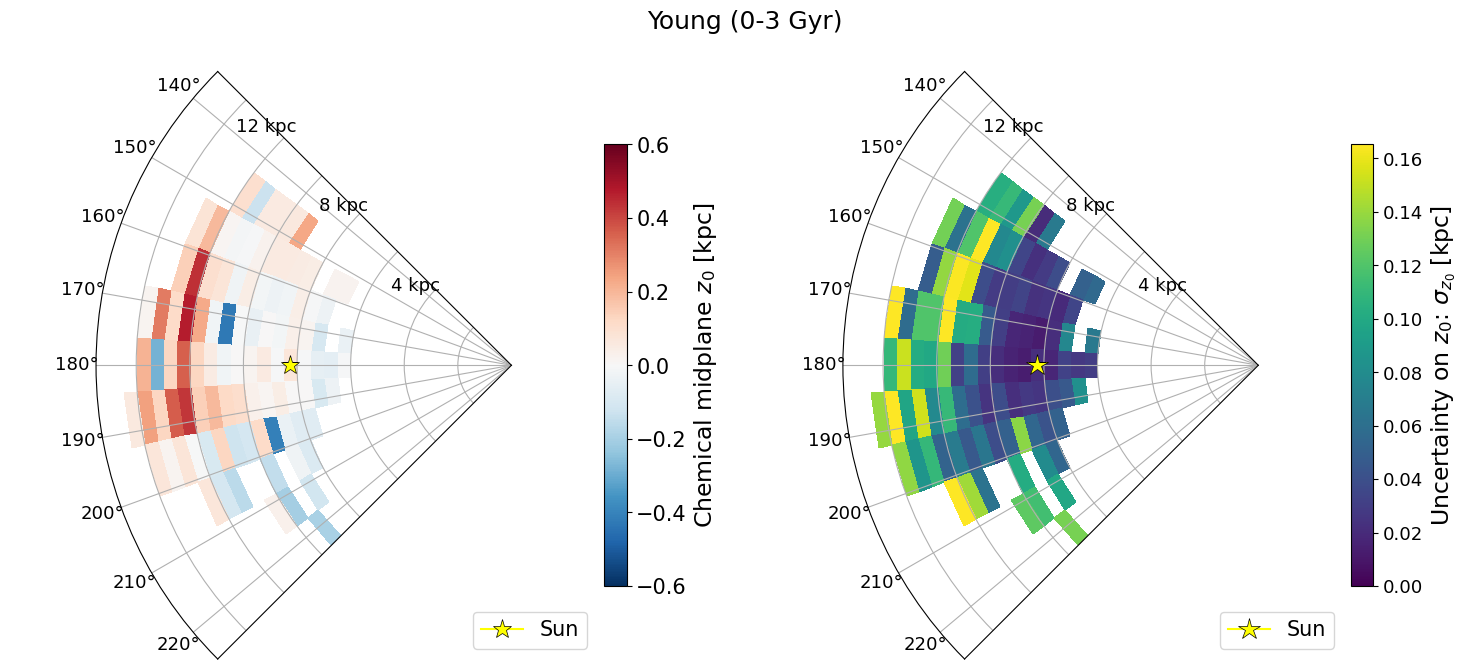

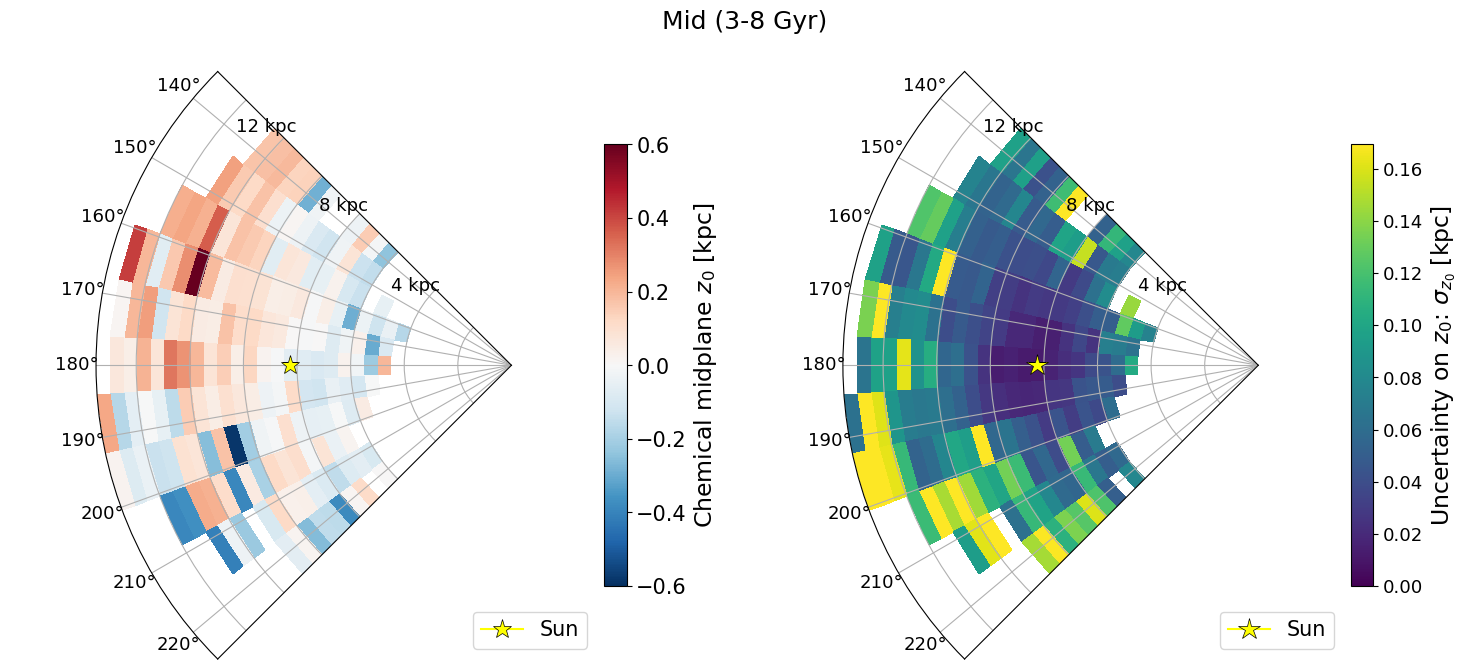

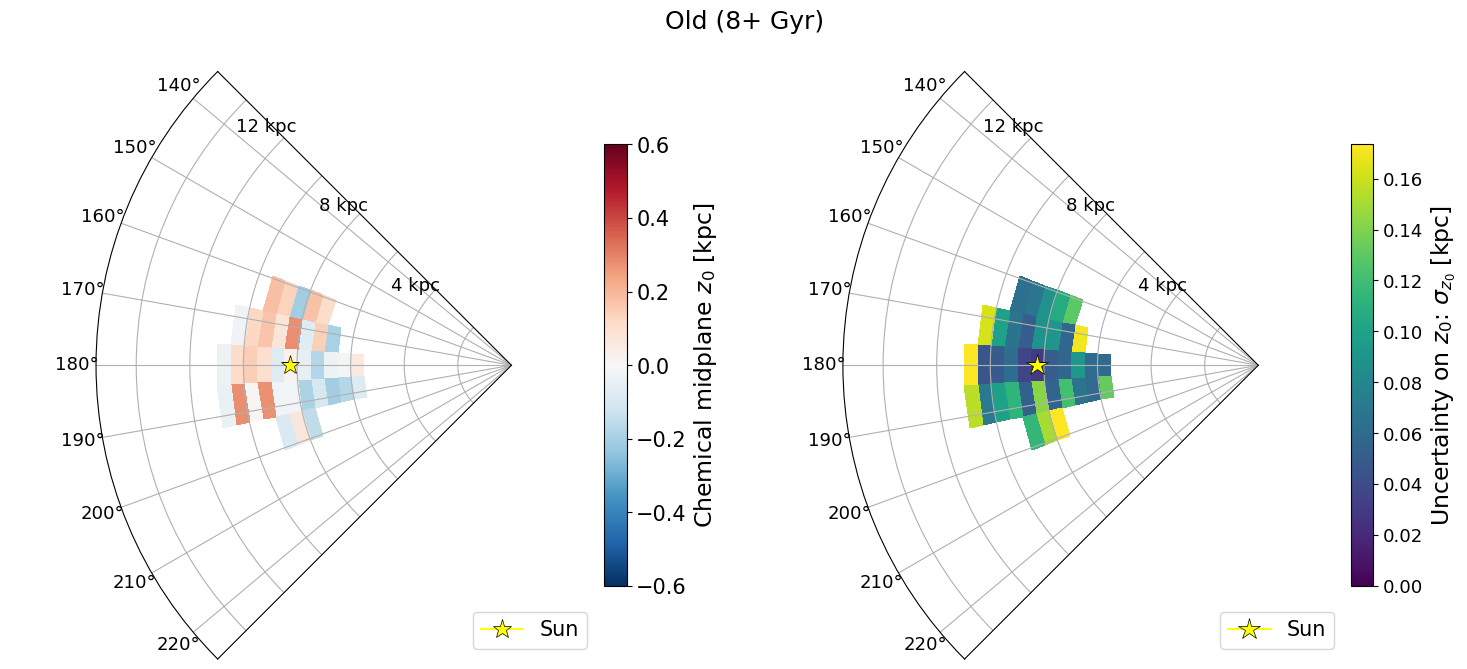

In [82]:
def plot_z0_heatmap(z0_med_bin, z0_std_bin, label):
    theta_edges = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi
    assert len(theta_edges) - 1 == n_seg, "theta_edges length must match number of crowded segments"

    T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
    Zmap_med = np.ma.masked_invalid(z0_med_bin)
    Zmap_std = np.ma.masked_invalid(z0_std_bin)
    std_max = float(np.nanpercentile(z0_std_bin[np.isfinite(z0_std_bin)], 95)) if np.isfinite(z0_std_bin).any() else 1.0
    theta_min = theta_edges[0]
    theta_max = theta_edges[-1]
    theta_sun = np.radians(180)
    R_sun = 8.275

    fig = plt.figure(figsize=(15, 7))
    fig.suptitle(label, fontsize=18)

    ax1 = plt.subplot(1, 2, 1, projection="polar")
    pcm1 = ax1.pcolormesh(T_mesh, R_mesh, Zmap_med, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
    cb1 = fig.colorbar(pcm1, ax=ax1, pad=0.01, shrink=0.7)
    cb1.set_label(r"Chemical midplane $z_0$ [kpc]", fontsize=17)
    cb1.ax.tick_params(labelsize=15)
    ax1.tick_params(labelsize=13)
    ax1.set_theta_zero_location("E")
    ax1.set_theta_direction(1)
    ax1.set_rmax(R_edges[-1])
    ax1.set_thetamin(np.degrees(theta_min))
    ax1.set_thetamax(np.degrees(theta_max))
    ax1.set_title("")
    for r in R_edges[R_edges % 4 == 0]:
        ax1.text(theta_min - np.radians(3), r, f"{r:.0f} kpc",
                 fontsize=13, ha="right", va="center")
    ax1.set_yticklabels([])
    ax1.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14,
             markeredgecolor="k", markeredgewidth=0.5, zorder=5, label="Sun")
    ax1.legend(loc="lower right", fontsize=15)

    ax2 = plt.subplot(1, 2, 2, projection="polar")
    pcm2 = ax2.pcolormesh(T_mesh, R_mesh, Zmap_std, cmap="viridis",
                          vmin=0.0, vmax=std_max, shading="flat")
    cb2 = fig.colorbar(pcm2, ax=ax2, pad=0.01, shrink=0.7)
    cb2.set_label(r"Uncertainty on $z_0$: $\sigma_{z_0}$ [kpc]", fontsize=17)
    cb2.ax.tick_params(labelsize=13)
    ax2.set_theta_zero_location("E")
    ax2.set_theta_direction(1)
    ax2.tick_params(labelsize=13)
    ax2.set_rmax(R_edges[-1])
    ax2.set_thetamin(np.degrees(theta_min))
    ax2.set_thetamax(np.degrees(theta_max))
    ax2.set_title("")
    for r in R_edges[R_edges % 4 == 0]:
        ax2.text(theta_min - np.radians(3), r, f"{r:.0f} kpc",
                 fontsize=13, ha="right", va="center")
    ax2.set_yticklabels([])
    ax2.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=16,
             markeredgecolor="k", markeredgewidth=0.5, zorder=5, label="Sun")
    ax2.legend(loc="lower right", fontsize=15)

    plt.tight_layout()
    plt.show()

plot_z0_heatmap(z0_med_young, z0_std_young, "Young (0-3 Gyr)")
plot_z0_heatmap(z0_med_mid,   z0_std_mid,   "Mid (3-8 Gyr)")
plot_z0_heatmap(z0_med_old,   z0_std_old,   "Old (8+ Gyr)")

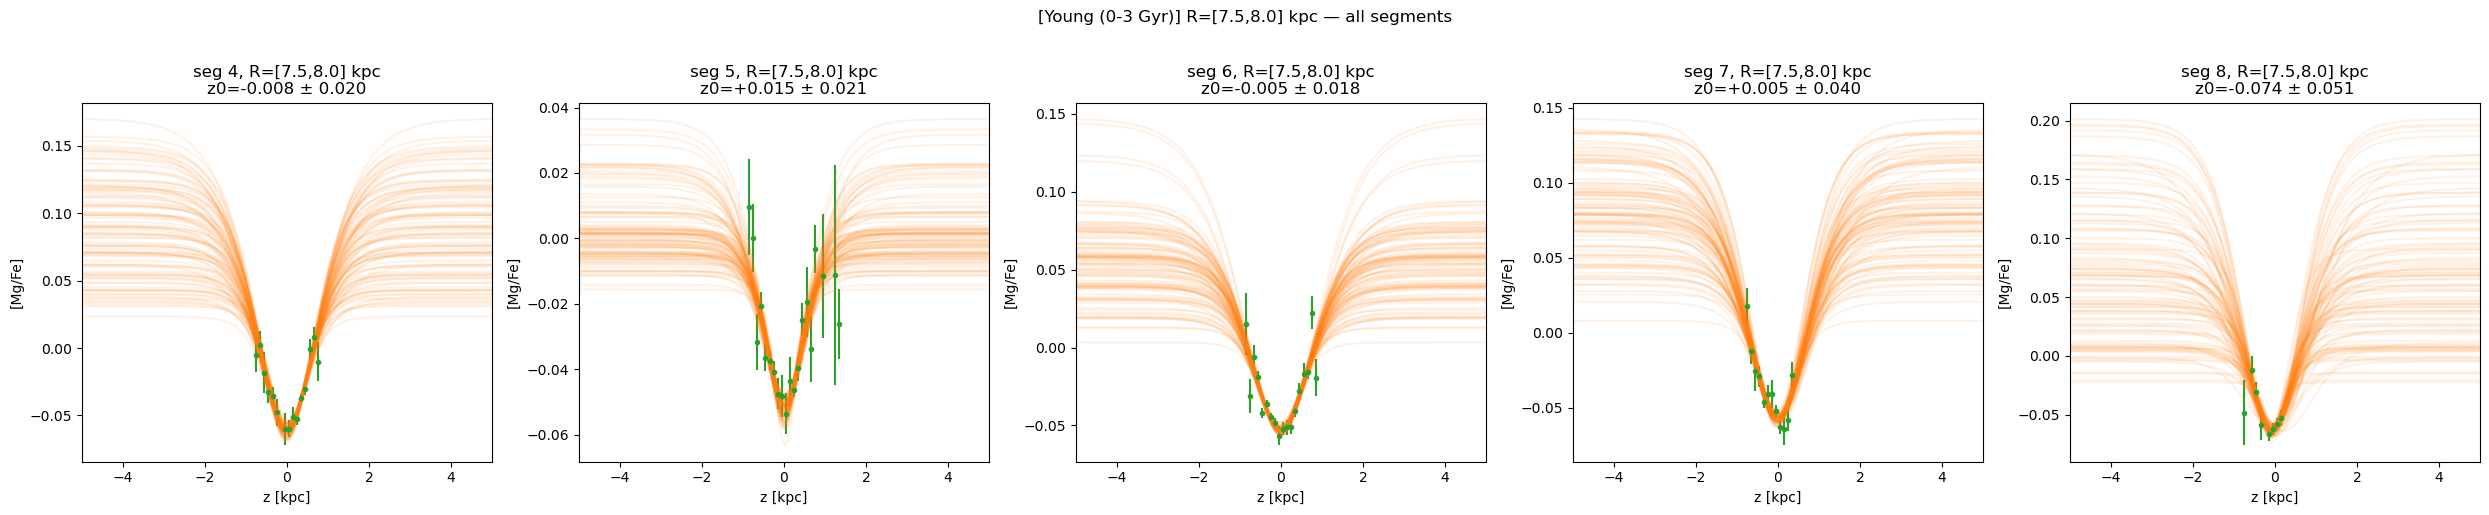

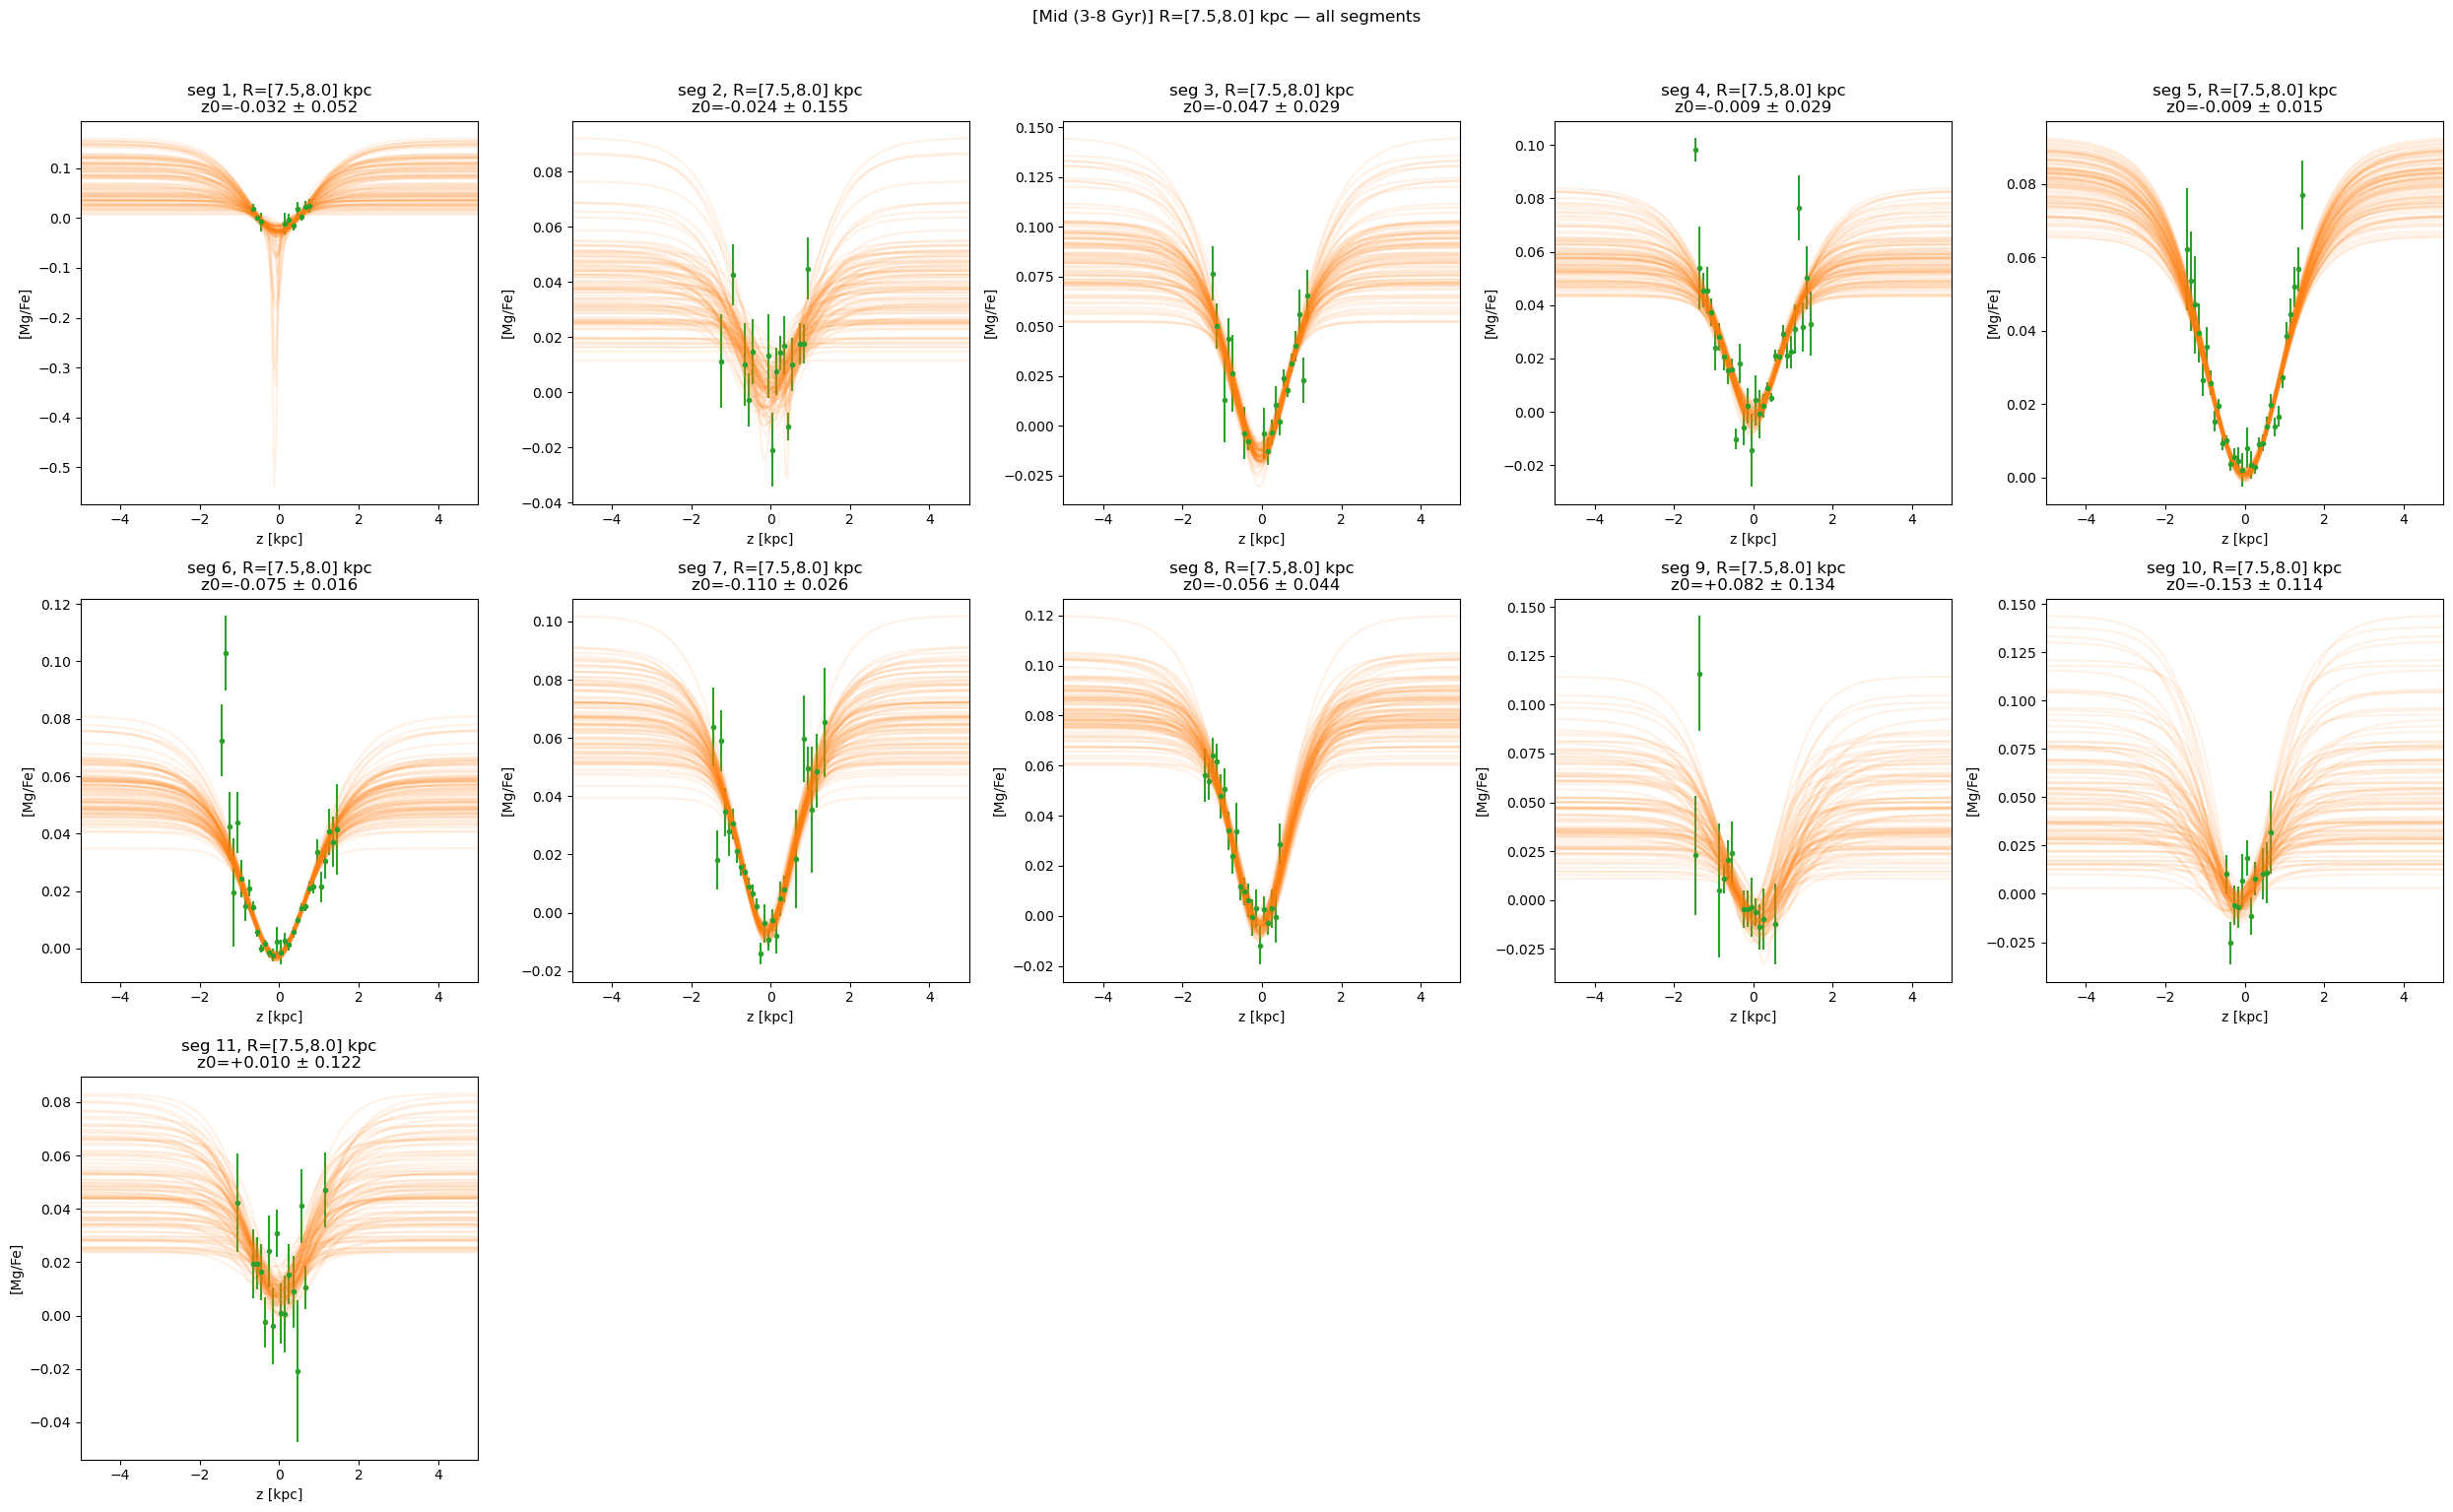

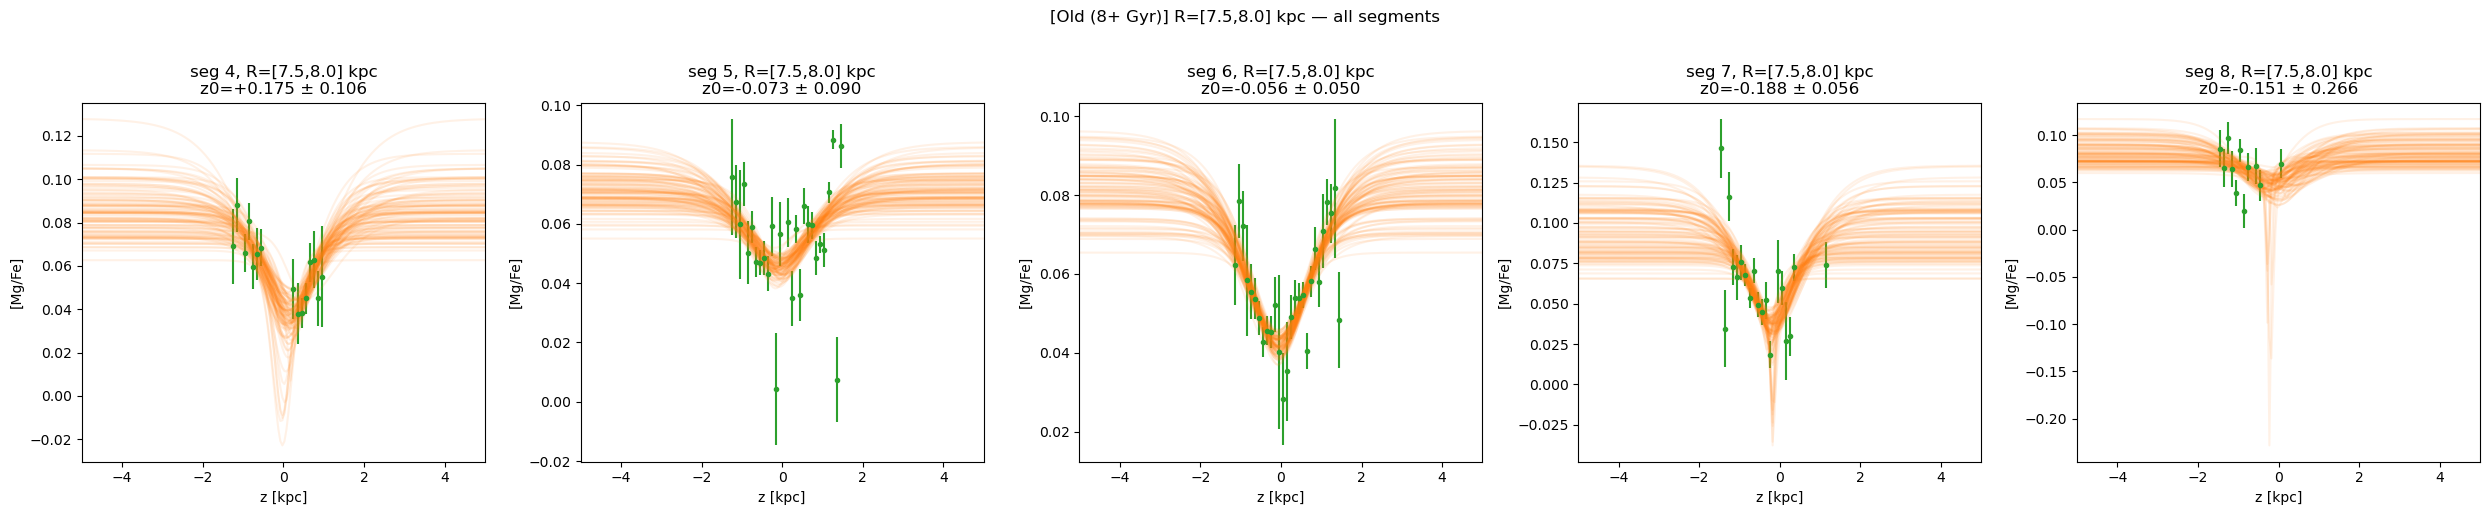

In [83]:
def plot_fit_diagnostics(per_cell_bin, z0_med_bin, z0_std_bin, label, R_focus=7.5):
    i_R_focus = np.searchsorted(R_edges, R_focus)
    cells_in_R = [(i_R, j_seg) for (i_R, j_seg) in per_cell_bin.keys() if i_R == i_R_focus]
    n_cells = len(cells_in_R)
    if n_cells == 0:
        print(f"[{label}] no fitted cells at R={R_focus} kpc (i_R_focus={i_R_focus}) -- "
              f"try a different R_focus")
        return

    n_cols = 5
    n_rows = int(np.ceil(n_cells / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), squeeze=False)
    z_grid = np.linspace(-5, 5, 200)

    for idx, (i_R, j_seg) in enumerate(cells_in_R):
        r, c = divmod(idx, n_cols)
        ax = axes[r, c]
        cell = per_cell_bin[(i_R, j_seg)]
        seg_id = SEG_PLOT_heat[j_seg]
        s = cell["samples"]

        ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                    color="C2", linestyle="", marker=".", label="binned mean")

        for i in range(min(100, len(s["A1"]))):
            cell_sample = {k: v[i] for k, v in s.items()}
            cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
            y_pred = mixture_of_sech2(z_grid, cell_sample["A1"], cell_sample["A2"],
                                      cell_sample["h1"], cell_sample["h2"],
                                      cell_sample["z0"]) + cell_sample["offset"]
            ax.plot(z_grid, y_pred, color="C1", alpha=0.1)

        ax.set_xlabel("z [kpc]")
        ax.set_ylabel("[Mg/Fe]")
        ax.set_title(f"seg {seg_id}, R=[{R_edges[i_R]:.1f},{R_edges[i_R+1]:.1f}] kpc\n"
                     f"z0={z0_med_bin[i_R,j_seg]:+.3f} \u00b1 {z0_std_bin[i_R,j_seg]:.3f}")
        ax.set_xlim(-5, 5)

    for idx in range(n_cells, n_rows * n_cols):
        r, c = divmod(idx, n_cols)
        axes[r, c].axis("off")

    plt.suptitle(f"[{label}] R=[{R_edges[i_R_focus]:.1f},{R_edges[i_R_focus+1]:.1f}] kpc \u2014 all segments", y=1.02)
    plt.tight_layout()
    plt.show()

plot_fit_diagnostics(per_cell_young, z0_med_young, z0_std_young, "Young (0-3 Gyr)")
plot_fit_diagnostics(per_cell_mid,   z0_med_mid,   z0_std_mid,   "Mid (3-8 Gyr)")
plot_fit_diagnostics(per_cell_old,   z0_med_old,   z0_std_old,   "Old (8+ Gyr)")

[young] fitting radial bins:   0%|                       | 0/23 [00:00<?, ?it/s]/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:13: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:14: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:24: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
[young] fitting radial bins:   4%|▋              | 1/23 [00:07<02:46,  7.58s/it]

[young] R=[3.5,4.5]: fit ok, n_stars=186


[young] fitting radial bins:   9%|█▎             | 2/23 [00:15<02:46,  7.93s/it]

[young] R=[4.0,5.0]: fit ok, n_stars=294


[young] fitting radial bins:  13%|█▉             | 3/23 [00:28<03:23, 10.17s/it]

...

[old] R=[11.5,12.5]: fit ok, n_stars=378


[old] fitting radial bins:  78%|████████████▌   | 18/23 [02:47<00:42,  8.52s/it]

[old] R=[12.0,13.0]: fit ok, n_stars=286


[old] fitting radial bins: 100%|████████████████| 23/23 [02:55<00:00,  7.64s/it]

[old] R=[12.5,13.5]: fit ok, n_stars=187
[old] R=[13.0,14.0]: skipping, only 6 good bins
[old] R=[13.5,14.5]: skipping, only 3 good bins
[old] R=[14.0,15.0]: skipping, only 0 good bins
[old] R=[14.5,15.5]: skipping, only 0 good bins
[old] fits complete: 19/23


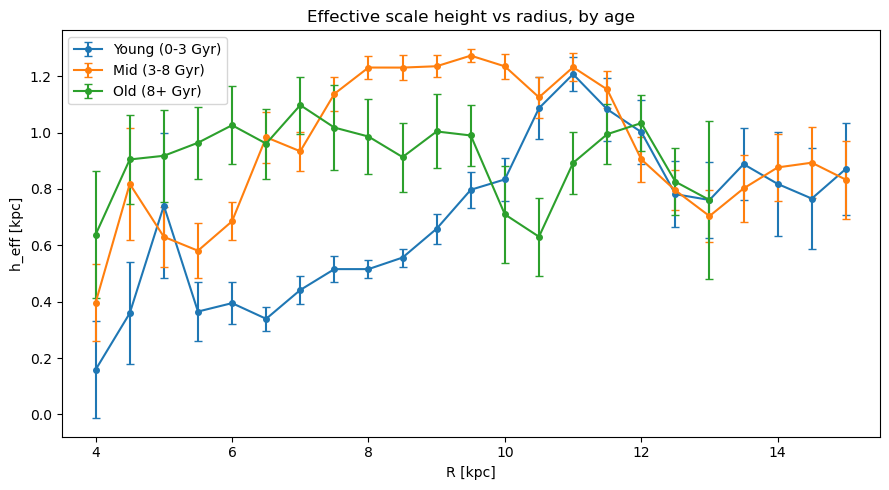

In [95]:
from tqdm import tqdm
import jax.random as jr
from scipy.optimize import brentq

R_centers_flare = np.arange(4, 15 + 1e-3, 0.5)
R_width = 1.0
n_R_flare = len(R_centers_flare)


def fit_flare_bin(R_arr, Z_arr, mgfe_arr, err_arr, label, results_path):
    """Same radial-only overlapping-bin fit as your Section 9 flare cell,
    parameterized over which stars to use."""
    R_arr    = np.asarray(R_arr)
    Z_arr    = np.asarray(Z_arr)
    mgfe_arr = np.asarray(mgfe_arr)
    err_arr  = np.asarray(err_arr)

    m_base = (
        np.isfinite(R_arr) & np.isfinite(Z_arr)
        & np.isfinite(mgfe_arr) & np.isfinite(err_arr)
        & (err_arr > 0)
    )

    per_R_flare = {}
    key = jr.PRNGKey(0)

    for i_R in tqdm(range(n_R_flare), desc=f"[{label}] fitting radial bins"):
        Rlo = R_centers_flare[i_R] - R_width / 2
        Rhi = R_centers_flare[i_R] + R_width / 2

        m = m_base & (R_arr >= Rlo) & (R_arr < Rhi)
        n_stars = int(m.sum())

        if n_stars < minN_seg_total:
            print(f"[{label}] R=[{Rlo:.1f},{Rhi:.1f}]: skipping, only {n_stars} stars")
            continue

        z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(
            Z_arr[m], mgfe_arr[m], err_arr[m]
        )

        good = (
            np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
            & (counts >= min_bin_count)
            & (z_binc >= z_fit_min) & (z_binc <= z_fit_max)
        )

        if good.sum() < min_bins_for_fit:
            print(f"[{label}] R=[{Rlo:.1f},{Rhi:.1f}]: skipping, only {good.sum()} good bins")
            continue

        try:
            key, sub = jr.split(key)
            sampler = fit_sech2(
                np.asarray(z_binc[good], float),
                np.asarray(mean_mg_fe[good], float),
                np.asarray(mean_mg_fe_err[good], float),
                sub,
                progress_bar=False
            )
            samples = sampler.get_samples()
            per_R_flare[i_R] = {
                "Rlo": Rlo, "Rhi": Rhi,
                "n_stars": n_stars,
                "z_binc": np.asarray(z_binc[good]),
                "mean": np.asarray(mean_mg_fe[good]),
                "err": np.asarray(mean_mg_fe_err[good]),
                "samples": {k: np.asarray(v) for k, v in samples.items()},
            }
            print(f"[{label}] R=[{Rlo:.1f},{Rhi:.1f}]: fit ok, n_stars={n_stars}")
        except Exception as e:
            print(f"[{label}] R=[{Rlo:.1f},{Rhi:.1f}]: fit failed -> {e}")

    print(f"[{label}] fits complete: {len(per_R_flare)}/{n_R_flare}")

    with open(results_path, "wb") as f:
        pickle.dump(per_R_flare, f)

    return per_R_flare


def root_func(z, pars):
    Ystar = mixture_of_sech2(
        z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], pars["z0"]
    )
    return Ystar - 0.5 * (pars["A1"] + pars["A2"])


def compute_h_eff_flare(per_R_flare):
    """Same h_eff computation as your Section 9 flare cell, minus the pickle reload."""
    h_eff_med = np.full(n_R_flare, np.nan)
    h_eff_std = np.full(n_R_flare, np.nan)

    for i_R, cell in per_R_flare.items():
        s = cell["samples"]
        h_effs = []
        for i in range(256):
            cell_sample = {k: v[i] for k, v in s.items()}
            cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
            hi = 8 * max(cell_sample["h1"], cell_sample["h2"])
            try:
                zstar = brentq(root_func, cell_sample["z0"] + 1e-9, hi, args=(cell_sample,))
                h_effs.append(zstar - cell_sample["z0"])
            except ValueError:
                continue

        if len(h_effs) > 0:
            h_effs = np.array(h_effs)
            h_eff_med[i_R] = np.median(h_effs)
            pcl = np.percentile(h_effs, [16, 84])
            h_eff_std[i_R] = 0.5 * (pcl[1] - pcl[0])

    return h_eff_med, h_eff_std


# fit each age bin
per_R_flare_young = fit_flare_bin(
    R_star[young_star_mask], Z_star[young_star_mask],
    mgfe_star[young_star_mask], mgfe_err_star[young_star_mask],
    label="young", results_path="per_R_flare_young.pkl",
)
per_R_flare_mid = fit_flare_bin(
    R_star[mid_star_mask], Z_star[mid_star_mask],
    mgfe_star[mid_star_mask], mgfe_err_star[mid_star_mask],
    label="mid", results_path="per_R_flare_mid.pkl",
)
per_R_flare_old = fit_flare_bin(
    R_star[old_star_mask], Z_star[old_star_mask],
    mgfe_star[old_star_mask], mgfe_err_star[old_star_mask],
    label="old", results_path="per_R_flare_old.pkl",
)

# compute h_eff for each
h_eff_med_young, h_eff_std_young = compute_h_eff_flare(per_R_flare_young)
h_eff_med_mid,   h_eff_std_mid   = compute_h_eff_flare(per_R_flare_mid)
h_eff_med_old,   h_eff_std_old   = compute_h_eff_flare(per_R_flare_old)

# one panel, three lines
fig, ax = plt.subplots(figsize=(9, 5))

ax.errorbar(R_centers_flare, h_eff_med_young, yerr=h_eff_std_young,
            fmt="o-", ms=4, capsize=3, color="C0", label="Young (0-3 Gyr)")
ax.errorbar(R_centers_flare, h_eff_med_mid, yerr=h_eff_std_mid,
            fmt="o-", ms=4, capsize=3, color="C1", label="Mid (3-8 Gyr)")
ax.errorbar(R_centers_flare, h_eff_med_old, yerr=h_eff_std_old,
            fmt="o-", ms=4, capsize=3, color="C2", label="Old (8+ Gyr)")

ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel("h_eff [kpc]")
ax.set_title("Effective scale height vs radius, by age")
ax.set_xlim(R_centers_flare[0] - R_width/2, R_centers_flare[-1] + R_width/2)
plt.tight_layout()
plt.show()

## astronn distances

In [84]:
t2_sdss_id = np.asarray(t2["sdss_id"])
dist_col = np.asarray(t2["dist_bugfix"], float)
if dist_col.ndim > 1:
    dist_col = dist_col.ravel()

valid_dist_mask = (
    np.isfinite(dist_col) & (dist_col > 0) & (dist_col < 50_000) & (t2_sdss_id != -1)
)
t2_sdss_id_valid = t2_sdss_id[valid_dist_mask]
dist_valid = dist_col[valid_dist_mask]
id_to_dist = dict(zip(t2_sdss_id_valid, dist_valid))

final_sdss_id = np.asarray(t_final["sdss_id"])
has_valid_dist_final = np.isin(final_sdss_id, t2_sdss_id_valid)

t_final_astroNN = t_final[has_valid_dist_final]
dist_bugfix_pc = np.array([id_to_dist[sid] for sid in final_sdss_id[has_valid_dist_final]])

print(f"t_final stars kept (valid dist_bugfix): {len(t_final_astroNN)} / {len(t_final)} "
      f"({100*len(t_final_astroNN)/len(t_final):.1f}%)")

t_final stars kept (valid dist_bugfix): 233068 / 391384 (59.5%)


In [85]:
def build_star_pack_custom_dist(table, dist_pc,
                                galcen_distance_kpc=8.275,
                                galcen_v_sun=(8, 254, 8),
                                rmax_keep=16.0):
    """Same as build_star_pack, but uses a supplied distance (pc), aligned
    row-by-row with `table`, instead of deriving it from zgr_plx."""
    t_use = table
    dist = Distance(np.asarray(dist_pc, float) * u.pc)

    galcen_frame = coord.Galactocentric(
        galcen_distance=galcen_distance_kpc * u.kpc,
        galcen_v_sun=list(galcen_v_sun) * u.km/u.s
    )

    c = SkyCoord(
        ra=col_to_float_array(t_use, "ra") * u.deg,
        dec=col_to_float_array(t_use, "dec") * u.deg,
        distance=dist,
        pm_ra_cosdec=col_to_float_array(t_use, "pmra") * u.mas/u.yr,
        pm_dec=col_to_float_array(t_use, "pmde") * u.mas/u.yr,
        radial_velocity=col_to_float_array(t_use, "v_rad") * u.km/u.s,
    )
    gc = c.transform_to(galcen_frame)

    X_all = gc.x.to_value(u.kpc)
    Y_all = gc.y.to_value(u.kpc)
    Z_all = gc.z.to_value(u.kpc)
    R_all = np.sqrt(X_all**2 + Y_all**2)
    phi_all = np.arctan2(Y_all, X_all)
    mgfe_all = col_to_float_array(t_use, "mg_h") - col_to_float_array(t_use, "fe_h")

    finite = (
        np.isfinite(X_all) & np.isfinite(Y_all) & np.isfinite(Z_all) &
        np.isfinite(R_all) & np.isfinite(phi_all) & np.isfinite(mgfe_all)
    )

    X_star, Y_star, Z_star = X_all[finite], Y_all[finite], Z_all[finite]
    R_star, phi_star, mgfe_star = R_all[finite], phi_all[finite], mgfe_all[finite]
    t_star = t_use[finite]

    if rmax_keep is not None:
        mR = R_star < rmax_keep
        X_star, Y_star, Z_star = X_star[mR], Y_star[mR], Z_star[mR]
        R_star, phi_star, mgfe_star = R_star[mR], phi_star[mR], mgfe_star[mR]
        t_star = t_star[mR]

    star_pack = {"X_star": X_star, "Y_star": Y_star, "Z_star": Z_star,
                 "R_star": R_star, "phi_star": phi_star,
                 "mgfe_star": mgfe_star, "t_star": t_star}
    diagnostics = {"input_size": len(table), "after_finite_cut": int(finite.sum()),
                    "final_size": len(R_star), "rmax_keep": rmax_keep}
    return star_pack, diagnostics

In [86]:
star_pack_astroNN, star_diag_astroNN = build_star_pack_custom_dist(
    t_final_astroNN, dist_bugfix_pc, rmax_keep=16
)

R_star_astroNN    = star_pack_astroNN["R_star"]
Z_star_astroNN    = star_pack_astroNN["Z_star"]
phi_star_astroNN  = star_pack_astroNN["phi_star"]
mgfe_star_astroNN = star_pack_astroNN["mgfe_star"]
t_star_astroNN    = star_pack_astroNN["t_star"]

segm_astroNN, crowd_bounds_astroNN, window_edges_astroNN, seg_diag_astroNN = build_segment_setup(
    phi_star_astroNN, phi0=np.pi, crowd_halfwidth_deg=45, n_crowd=11
)
SEG_PLOT_heat_astroNN = list(range(1, seg_diag_astroNN["n_crowd"] + 1))

e_mg_h_star_astroNN = col_to_float_array(t_star_astroNN, "e_mg_h")
e_fe_h_star_astroNN = col_to_float_array(t_star_astroNN, "e_fe_h")
mgfe_err_star_astroNN = np.sqrt(e_mg_h_star_astroNN**2 + e_fe_h_star_astroNN**2)

print("astroNN star_pack final size:", star_diag_astroNN["final_size"])

astroNN star_pack final size: 231656


In [87]:
z0_med_astroNN, z0_std_astroNN, per_cell_astroNN = run_grid_fit(
    R_star_astroNN, Z_star_astroNN, mgfe_star_astroNN, mgfe_err_star_astroNN,
    segm_astroNN, label="astroNN", results_path="sech2_mcmc_results_astroNN.pkl",
)

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:13: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:14: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:24: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


  [astroNN] done 140/330
  [astroNN] done 160/330
  [astroNN] done 180/330
  [astroNN] done 200/330
  [astroNN] done 220/330
  [astroNN] done 240/330
  [astroNN] done 260/330
  [astroNN] done 280/330
[astroNN] fits complete: 158 / 330


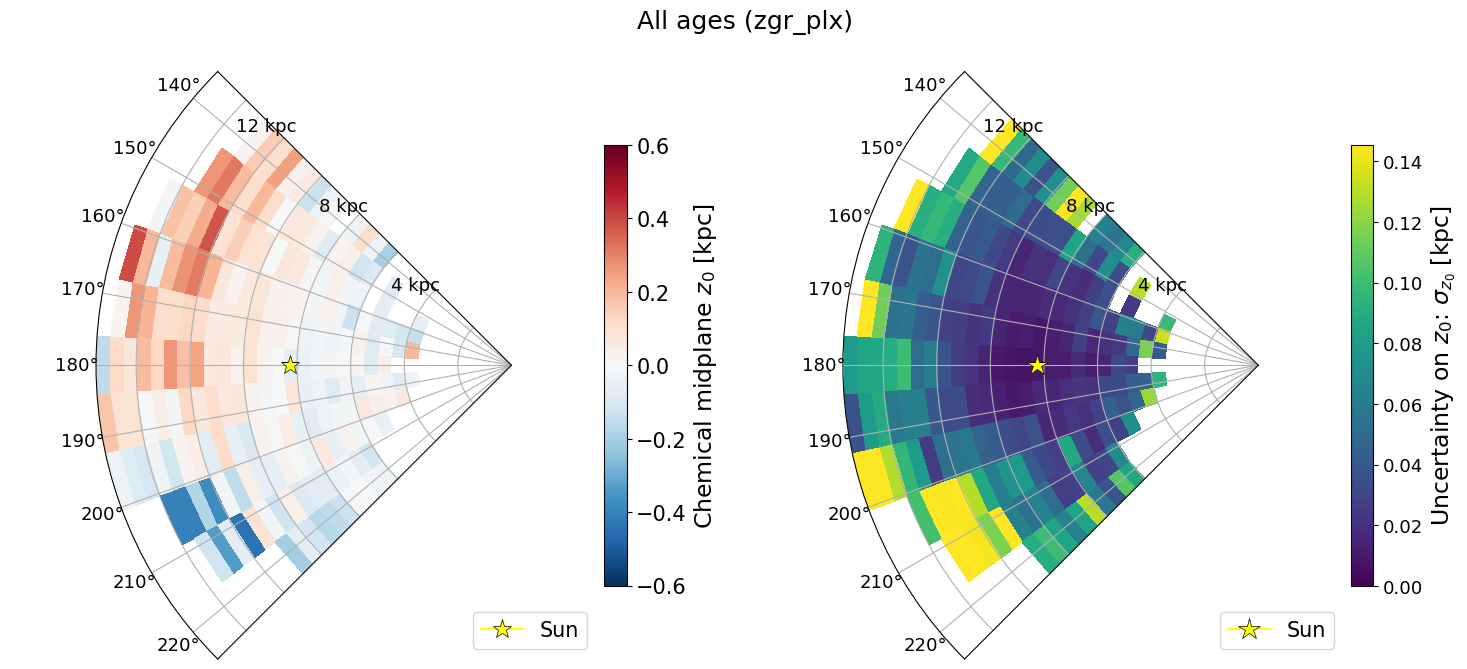

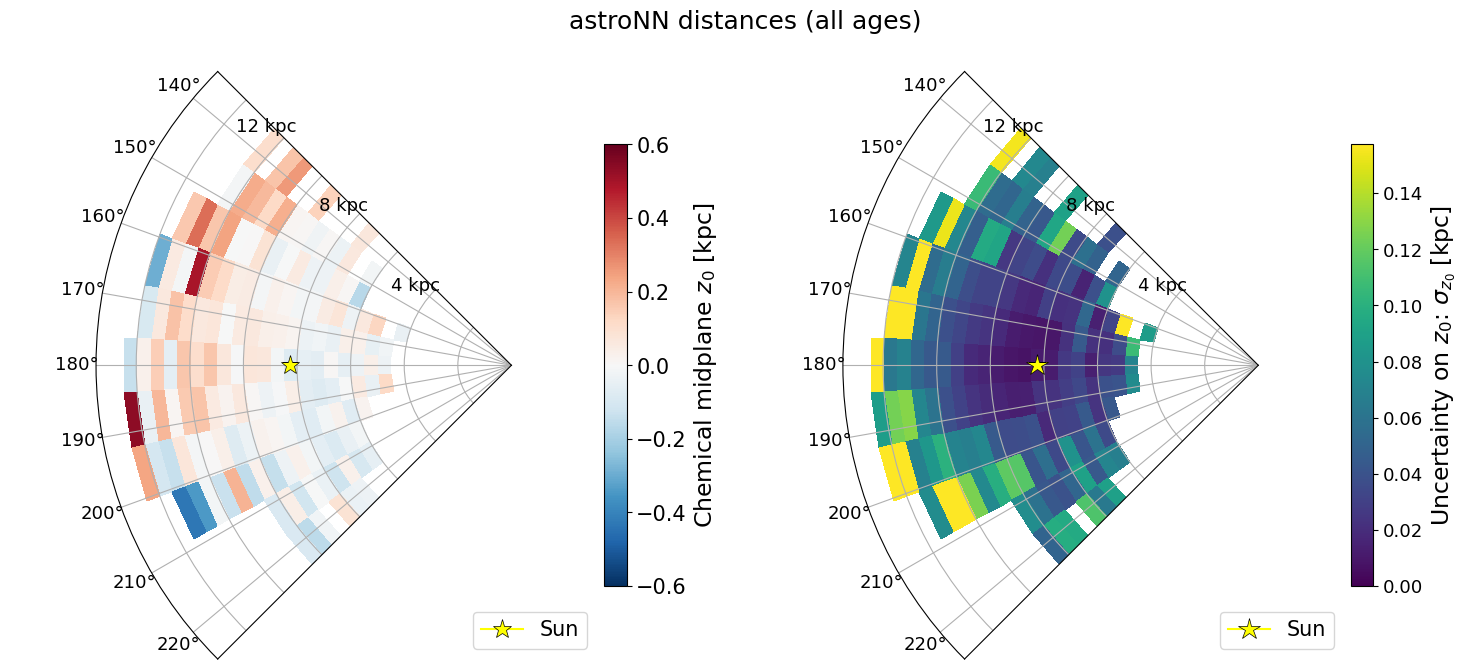

In [88]:
def plot_z0_heatmap(z0_med_bin, z0_std_bin, label, crowd_bounds, n_seg):
    theta_edges = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi
    assert len(theta_edges) - 1 == n_seg, "theta_edges length must match number of crowded segments"

    T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
    Zmap_med = np.ma.masked_invalid(z0_med_bin)
    Zmap_std = np.ma.masked_invalid(z0_std_bin)
    std_max = float(np.nanpercentile(z0_std_bin[np.isfinite(z0_std_bin)], 95)) if np.isfinite(z0_std_bin).any() else 1.0
    theta_min = theta_edges[0]
    theta_max = theta_edges[-1]
    theta_sun = np.radians(180)
    R_sun = 8.275

    fig = plt.figure(figsize=(15, 7))
    fig.suptitle(label, fontsize=18)

    ax1 = plt.subplot(1, 2, 1, projection="polar")
    pcm1 = ax1.pcolormesh(T_mesh, R_mesh, Zmap_med, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
    cb1 = fig.colorbar(pcm1, ax=ax1, pad=0.01, shrink=0.7)
    cb1.set_label(r"Chemical midplane $z_0$ [kpc]", fontsize=17)
    cb1.ax.tick_params(labelsize=15)
    ax1.tick_params(labelsize=13)
    ax1.set_theta_zero_location("E")
    ax1.set_theta_direction(1)
    ax1.set_rmax(R_edges[-1])
    ax1.set_thetamin(np.degrees(theta_min))
    ax1.set_thetamax(np.degrees(theta_max))
    ax1.set_title("")
    for r in R_edges[R_edges % 4 == 0]:
        ax1.text(theta_min - np.radians(3), r, f"{r:.0f} kpc",
                 fontsize=13, ha="right", va="center")
    ax1.set_yticklabels([])
    ax1.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14,
             markeredgecolor="k", markeredgewidth=0.5, zorder=5, label="Sun")
    ax1.legend(loc="lower right", fontsize=15)

    ax2 = plt.subplot(1, 2, 2, projection="polar")
    pcm2 = ax2.pcolormesh(T_mesh, R_mesh, Zmap_std, cmap="viridis",
                          vmin=0.0, vmax=std_max, shading="flat")
    cb2 = fig.colorbar(pcm2, ax=ax2, pad=0.01, shrink=0.7)
    cb2.set_label(r"Uncertainty on $z_0$: $\sigma_{z_0}$ [kpc]", fontsize=17)
    cb2.ax.tick_params(labelsize=13)
    ax2.set_theta_zero_location("E")
    ax2.set_theta_direction(1)
    ax2.tick_params(labelsize=13)
    ax2.set_rmax(R_edges[-1])
    ax2.set_thetamin(np.degrees(theta_min))
    ax2.set_thetamax(np.degrees(theta_max))
    ax2.set_title("")
    for r in R_edges[R_edges % 4 == 0]:
        ax2.text(theta_min - np.radians(3), r, f"{r:.0f} kpc",
                 fontsize=13, ha="right", va="center")
    ax2.set_yticklabels([])
    ax2.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=16,
             markeredgecolor="k", markeredgewidth=0.5, zorder=5, label="Sun")
    ax2.legend(loc="lower right", fontsize=15)

    plt.tight_layout()
    plt.show()


# original full-sample map (zgr_plx distances)
plot_z0_heatmap(z0_med, z0_std, "All ages (zgr_plx)", crowd_bounds, n_seg)

# astroNN-distance map
plot_z0_heatmap(z0_med_astroNN, z0_std_astroNN, "astroNN distances (all ages)",
                crowd_bounds_astroNN, len(SEG_PLOT_heat_astroNN))

[astroNN] fitting radial bins:   0%|                     | 0/23 [00:00<?, ?it/s]/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:13: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:14: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:24: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
[astroNN] fitting radial bins:   4%|▌            | 1/23 [00:11<04:05, 11.14s/it]

[astroNN] R=[3.5,4.5]: fit ok, n_stars=1036


[astroNN] fitting radial bins:   9%|█▏           | 2/23 [00:18<03:06,  8.87s/it]

[astroNN] R=[4.0,5.0]: fit ok, n_stars=1471


[astroNN] fitting radial bins:  13%|█▋           | 3/23 [00:24<02:35,  7.77s/it]

...

[astroNN] R=[13.5,14.5]: fit ok, n_stars=2367


[astroNN] fitting radial bins:  96%|███████████▍| 22/23 [05:15<00:10, 10.92s/it]

[astroNN] R=[14.0,15.0]: fit ok, n_stars=1465


[astroNN] fitting radial bins: 100%|████████████| 23/23 [05:22<00:00, 14.02s/it]

[astroNN] R=[14.5,15.5]: fit ok, n_stars=974
[astroNN] fits complete: 23/23


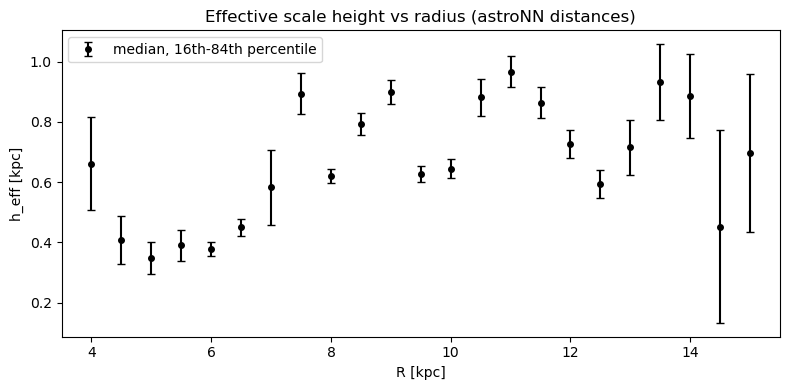

In [90]:
per_R_flare_astroNN = fit_flare_bin(
    R_star_astroNN, Z_star_astroNN, mgfe_star_astroNN, mgfe_err_star_astroNN,
    label="astroNN", results_path="per_R_flare_astroNN.pkl",
)

h_eff_med_astroNN, h_eff_std_astroNN = compute_h_eff_flare(per_R_flare_astroNN)

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers_flare, h_eff_med_astroNN, yerr=h_eff_std_astroNN,
            fmt="o", color="k", ms=4, capsize=3,
            label="median, 16th-84th percentile")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel("h_eff [kpc]")
ax.set_title("Effective scale height vs radius (astroNN distances)")
ax.set_xlim(R_centers_flare[0] - R_width/2, R_centers_flare[-1] + R_width/2)
plt.tight_layout()
plt.show()

## Heff heatmap

In [99]:
from scipy.optimize import brentq
from tqdm import tqdm

def compute_h_eff(pars, z_max=1.5):
    z0 = pars["z0"]
    half_max = 0.5 * (pars["A1"] + pars["A2"])

    f_z0 = mixture_of_sech2(z0, pars["A1"], pars["A2"], pars["h1"], pars["h2"], z0)
    f_zmax_right = mixture_of_sech2(z0 + z_max, pars["A1"], pars["A2"], pars["h1"], pars["h2"], z0)
    f_zmax_left = mixture_of_sech2(z0 - z_max, pars["A1"], pars["A2"], pars["h1"], pars["h2"], z0)

    try:
        if (f_z0 - half_max) * (f_zmax_right - half_max) < 0:
            zstar_right = brentq(
                lambda z: mixture_of_sech2(z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], z0) - half_max,
                z0 + 1e-3, z0 + z_max
            )
        else:
            return np.nan

        if (f_z0 - half_max) * (f_zmax_left - half_max) < 0:
            zstar_left = brentq(
                lambda z: mixture_of_sech2(z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], z0) - half_max,
                z0 - z_max, z0 - 1e-3
            )
        else:
            return np.nan

        return (zstar_right - zstar_left) / 2   # <- half-width instead of full width
    except ValueError:
        return np.nan


h_eff_med = np.full((n_R, n_seg), np.nan)
h_eff_std = np.full((n_R, n_seg), np.nan)

for (i_R, j_seg), cell in tqdm(per_cell.items(), desc="computing h_eff"):
    s = cell["samples"]
    h_effs = []
    for i in range(256):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        h_eff = compute_h_eff(cell_sample, z_max=2.0)
        if np.isfinite(h_eff):
            h_effs.append(h_eff)

    if len(h_effs) > 0:
        h_effs = np.array(h_effs)
        h_eff_med[i_R, j_seg] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std[i_R, j_seg] = 0.5 * (pcl[1] - pcl[0])

print(f"h_eff computed for {np.isfinite(h_eff_med).sum()} / {h_eff_med.size} cells")

computing h_eff: 100%|████████████████████████| 206/206 [02:27<00:00,  1.40it/s]

h_eff computed for 206 / 330 cells


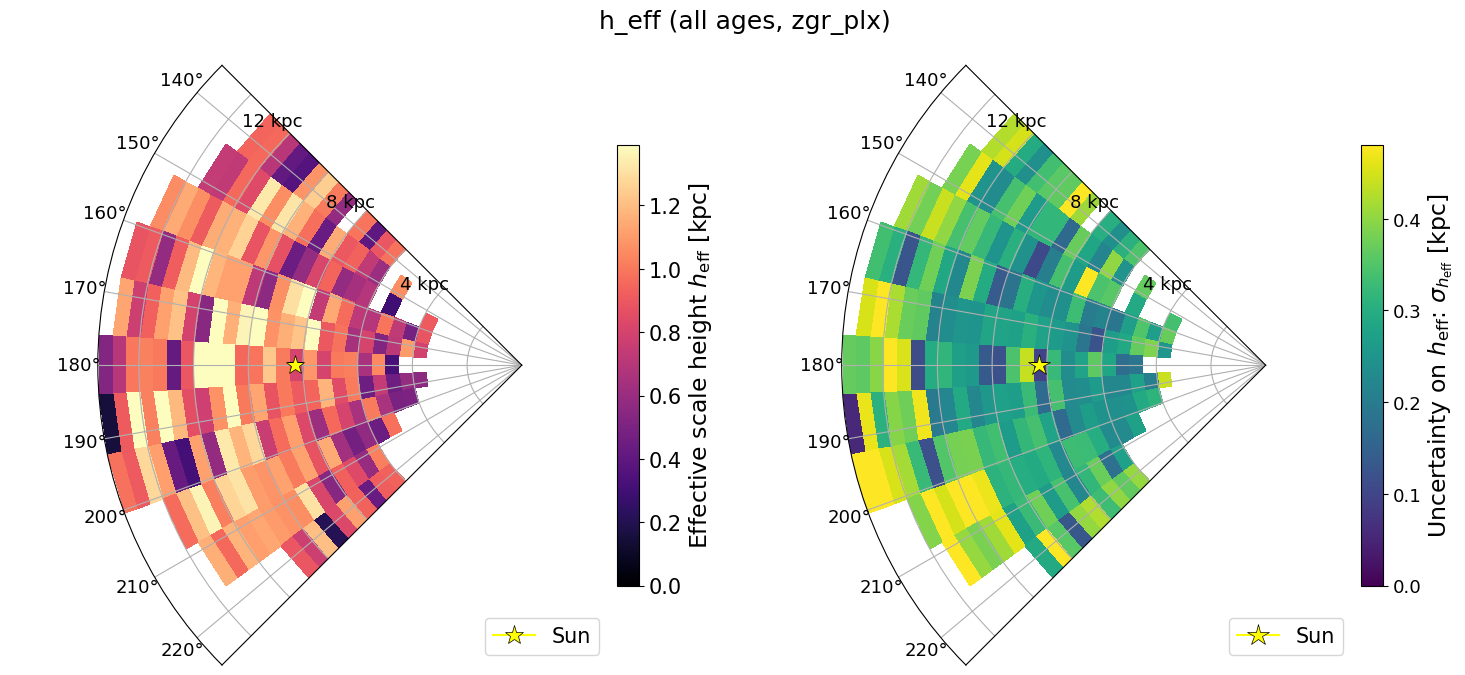

In [100]:
plot_h_eff_heatmap(h_eff_med, h_eff_std, "h_eff (all ages, zgr_plx)", crowd_bounds, n_seg)